In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
import os
import joblib

In [3]:
ml_logs_dir = 'ML logs copy'
if not os.path.exists(ml_logs_dir):
    os.makedirs(ml_logs_dir)

# Define subdirectories for models and graphs
models_dir = os.path.join(ml_logs_dir, 'models')
graphs_dir = os.path.join(ml_logs_dir, 'graphs')

if not os.path.exists(models_dir):
    os.makedirs(models_dir)

if not os.path.exists(graphs_dir):
    os.makedirs(graphs_dir)


In [4]:
Data="C:/Users/Tharunraj_S/Desktop/Mini_project\kidney_disease.csv"
df=pd.read_csv(Data)
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [5]:
df.shape

(400, 26)

In [6]:
df.columns

Index(['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr',
       'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'classification'],
      dtype='object')

In [7]:
# dropping id column
df.drop('id', axis = 1, inplace = True)

In [8]:
# rename column names to make it more meaningful
df.columns = ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell',
              'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
              'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count',
              'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema',
              'anemia', 'class']

In [9]:
df.columns

Index(['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar',
       'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria',
       'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
       'potassium', 'haemoglobin', 'packed_cell_volume',
       'white_blood_cell_count', 'red_blood_cell_count', 'hypertension',
       'diabetes_mellitus', 'coronary_artery_disease', 'appetite',
       'peda_edema', 'anemia', 'class'],
      dtype='object')

In [10]:
df.describe()

,age,blood_pressure,specific_gravity,albumin,sugar,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,haemoglobin
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  haemoglobin              3

In [12]:
# Printing unique values in data
for i in df.columns:
    print('unique values in "{}":\n'.format(i),df[i].unique())

unique values in "age":
 [48.  7. 62. 51. 60. 68. 24. 52. 53. 50. 63. 40. 47. 61. 21. 42. 75. 69.
 nan 73. 70. 65. 76. 72. 82. 46. 45. 35. 54. 11. 59. 67. 15. 55. 44. 26.
 64. 56.  5. 74. 38. 58. 71. 34. 17. 12. 43. 41. 57.  8. 39. 66. 81. 14.
 27. 83. 30.  4.  3.  6. 32. 80. 49. 90. 78. 19.  2. 33. 36. 37. 23. 25.
 20. 29. 28. 22. 79.]
unique values in "blood_pressure":
 [ 80.  50.  70.  90.  nan 100.  60. 110. 140. 180. 120.]
unique values in "specific_gravity":
 [1.02  1.01  1.005 1.015   nan 1.025]
unique values in "albumin":
 [ 1.  4.  2.  3.  0. nan  5.]
unique values in "sugar":
 [ 0.  3.  4.  1. nan  2.  5.]
unique values in "red_blood_cells":
 [nan 'normal' 'abnormal']
unique values in "pus_cell":
 ['normal' 'abnormal' nan]
unique values in "pus_cell_clumps":
 ['notpresent' 'present' nan]
unique values in "bacteria":
 ['notpresent' 'present' nan]
unique values in "blood_glucose_random":
 [121.  nan 423. 117. 106.  74. 100. 410. 138.  70. 490. 380. 208.  98.
 157.  76.  99. 114

In [13]:
#PREPROCESSING

In [14]:
# replace some incorrect values
df['diabetes_mellitus'].replace(to_replace = {'\tno':'no','\tyes':'yes',' yes':'yes'},inplace=True)

df['coronary_artery_disease'] = df['coronary_artery_disease'].replace(to_replace = '\tno', value='no')

df['class'] = df['class'].replace(to_replace = {'ckd\t': 'ckd', 'notckd': 'not ckd'})

In [15]:
# converting necessary columns to numerical type
df['packed_cell_volume'] = pd.to_numeric(df['packed_cell_volume'], errors='coerce')
df['white_blood_cell_count'] = pd.to_numeric(df['white_blood_cell_count'], errors='coerce')
df['red_blood_cell_count'] = pd.to_numeric(df['red_blood_cell_count'], errors='coerce')

In [16]:
df['class'] = df['class'].map({'not ckd': 0, 'ckd': 1})
df['class'] = pd.to_numeric(df['class'], errors='coerce')

In [17]:
# Extracting categorical and numerical columns
cat_cols = [col for col in df.columns if df[col].dtype == 'object']
num_cols = [col for col in df.columns if df[col].dtype != 'object']

In [18]:
df.head(10)

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,anemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,1
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,1
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,1
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,1
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,1
5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,74.0,...,39.0,7800.0,4.4,yes,yes,no,good,yes,no,1
6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,100.0,...,36.0,NaN,NaN,no,no,no,good,no,no,1
7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,410.0,...,44.0,6900.0,5.0,no,yes,no,good,yes,no,1
8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,138.0,...,33.0,9600.0,4.0,yes,yes,no,good,no,yes,1
9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,70.0,...,29.0,12100.0,3.7,yes,yes,no,poor,no,yes,1


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  haemoglobin              3

In [20]:
# checking for null values
df.isna().sum().sort_values(ascending = False)

red_blood_cells            152
red_blood_cell_count       131
white_blood_cell_count     106
potassium                   88
sodium                      87
packed_cell_volume          71
pus_cell                    65
haemoglobin                 52
sugar                       49
specific_gravity            47
albumin                     46
blood_glucose_random        44
blood_urea                  19
serum_creatinine            17
blood_pressure              12
age                          9
bacteria                     4
pus_cell_clumps              4
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
peda_edema                   1
anemia                       1
class                        0
dtype: int64

In [21]:
df[num_cols].isnull().sum().sort_values(ascending = False)

red_blood_cell_count      131
white_blood_cell_count    106
potassium                  88
sodium                     87
packed_cell_volume         71
haemoglobin                52
sugar                      49
specific_gravity           47
albumin                    46
blood_glucose_random       44
blood_urea                 19
serum_creatinine           17
blood_pressure             12
age                         9
class                       0
dtype: int64

In [22]:
df[cat_cols].isnull().sum().sort_values(ascending = False)

red_blood_cells            152
pus_cell                    65
pus_cell_clumps              4
bacteria                     4
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
peda_edema                   1
anemia                       1
dtype: int64

In [23]:
# filling null values, we will use two methods, random sampling for higher null values and mean/mode sampling for lower null values
def random_value_imputation(feature):
    random_sample = df[feature].dropna().sample(df[feature].isna().sum())
    random_sample.index = df[df[feature].isnull()].index
    df.loc[df[feature].isnull(), feature] = random_sample
    
def impute_mode(feature):
    mode = df[feature].mode()[0]
    df[feature] = df[feature].fillna(mode)

In [24]:
# filling num_cols null values using random sampling method
for col in num_cols:
    random_value_imputation(col)
    
df[num_cols].isnull().sum()

age                       0
blood_pressure            0
specific_gravity          0
albumin                   0
sugar                     0
blood_glucose_random      0
blood_urea                0
serum_creatinine          0
sodium                    0
potassium                 0
haemoglobin               0
packed_cell_volume        0
white_blood_cell_count    0
red_blood_cell_count      0
class                     0
dtype: int64

In [25]:
# filling "red_blood_cells" and "pus_cell" using random sampling method and rest of cat_cols using mode imputation
random_value_imputation('red_blood_cells')
random_value_imputation('pus_cell')

for col in cat_cols:
    impute_mode(col)
    
df[cat_cols].isnull().sum()

red_blood_cells            0
pus_cell                   0
pus_cell_clumps            0
bacteria                   0
hypertension               0
diabetes_mellitus          0
coronary_artery_disease    0
appetite                   0
peda_edema                 0
anemia                     0
dtype: int64

In [26]:
#Feature Encoding

In [27]:
# Printing unique values in cat_cols
for col in cat_cols:
    print(f"{col} has {df[col].nunique()} categories\n")

red_blood_cells has 2 categories

pus_cell has 2 categories

pus_cell_clumps has 2 categories

bacteria has 2 categories

hypertension has 2 categories

diabetes_mellitus has 2 categories

coronary_artery_disease has 2 categories

appetite has 2 categories

peda_edema has 2 categories

anemia has 2 categories



In [28]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [29]:
df.head(10)

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,anemia,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,1
1,7.0,50.0,1.020,4.0,0.0,0,1,0,0,165.0,...,38.0,6000.0,4.3,0,0,0,0,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,6.1,0,1,0,1,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,1
5,60.0,90.0,1.015,3.0,0.0,1,1,0,0,74.0,...,39.0,7800.0,4.4,1,1,0,0,1,0,1
6,68.0,70.0,1.010,0.0,0.0,1,1,0,0,100.0,...,36.0,5500.0,5.2,0,0,0,0,0,0,1
7,24.0,80.0,1.015,2.0,4.0,1,0,0,0,410.0,...,44.0,6900.0,5.0,0,1,0,0,1,0,1
8,52.0,100.0,1.015,3.0,0.0,1,0,1,0,138.0,...,33.0,9600.0,4.0,1,1,0,0,0,1,1
9,53.0,90.0,1.020,2.0,0.0,0,0,1,0,70.0,...,29.0,12100.0,3.7,1,1,0,1,0,1,1


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      400 non-null    float64
 1   blood_pressure           400 non-null    float64
 2   specific_gravity         400 non-null    float64
 3   albumin                  400 non-null    float64
 4   sugar                    400 non-null    float64
 5   red_blood_cells          400 non-null    int32  
 6   pus_cell                 400 non-null    int32  
 7   pus_cell_clumps          400 non-null    int32  
 8   bacteria                 400 non-null    int32  
 9   blood_glucose_random     400 non-null    float64
 10  blood_urea               400 non-null    float64
 11  serum_creatinine         400 non-null    float64
 12  sodium                   400 non-null    float64
 13  potassium                400 non-null    float64
 14  haemoglobin              4

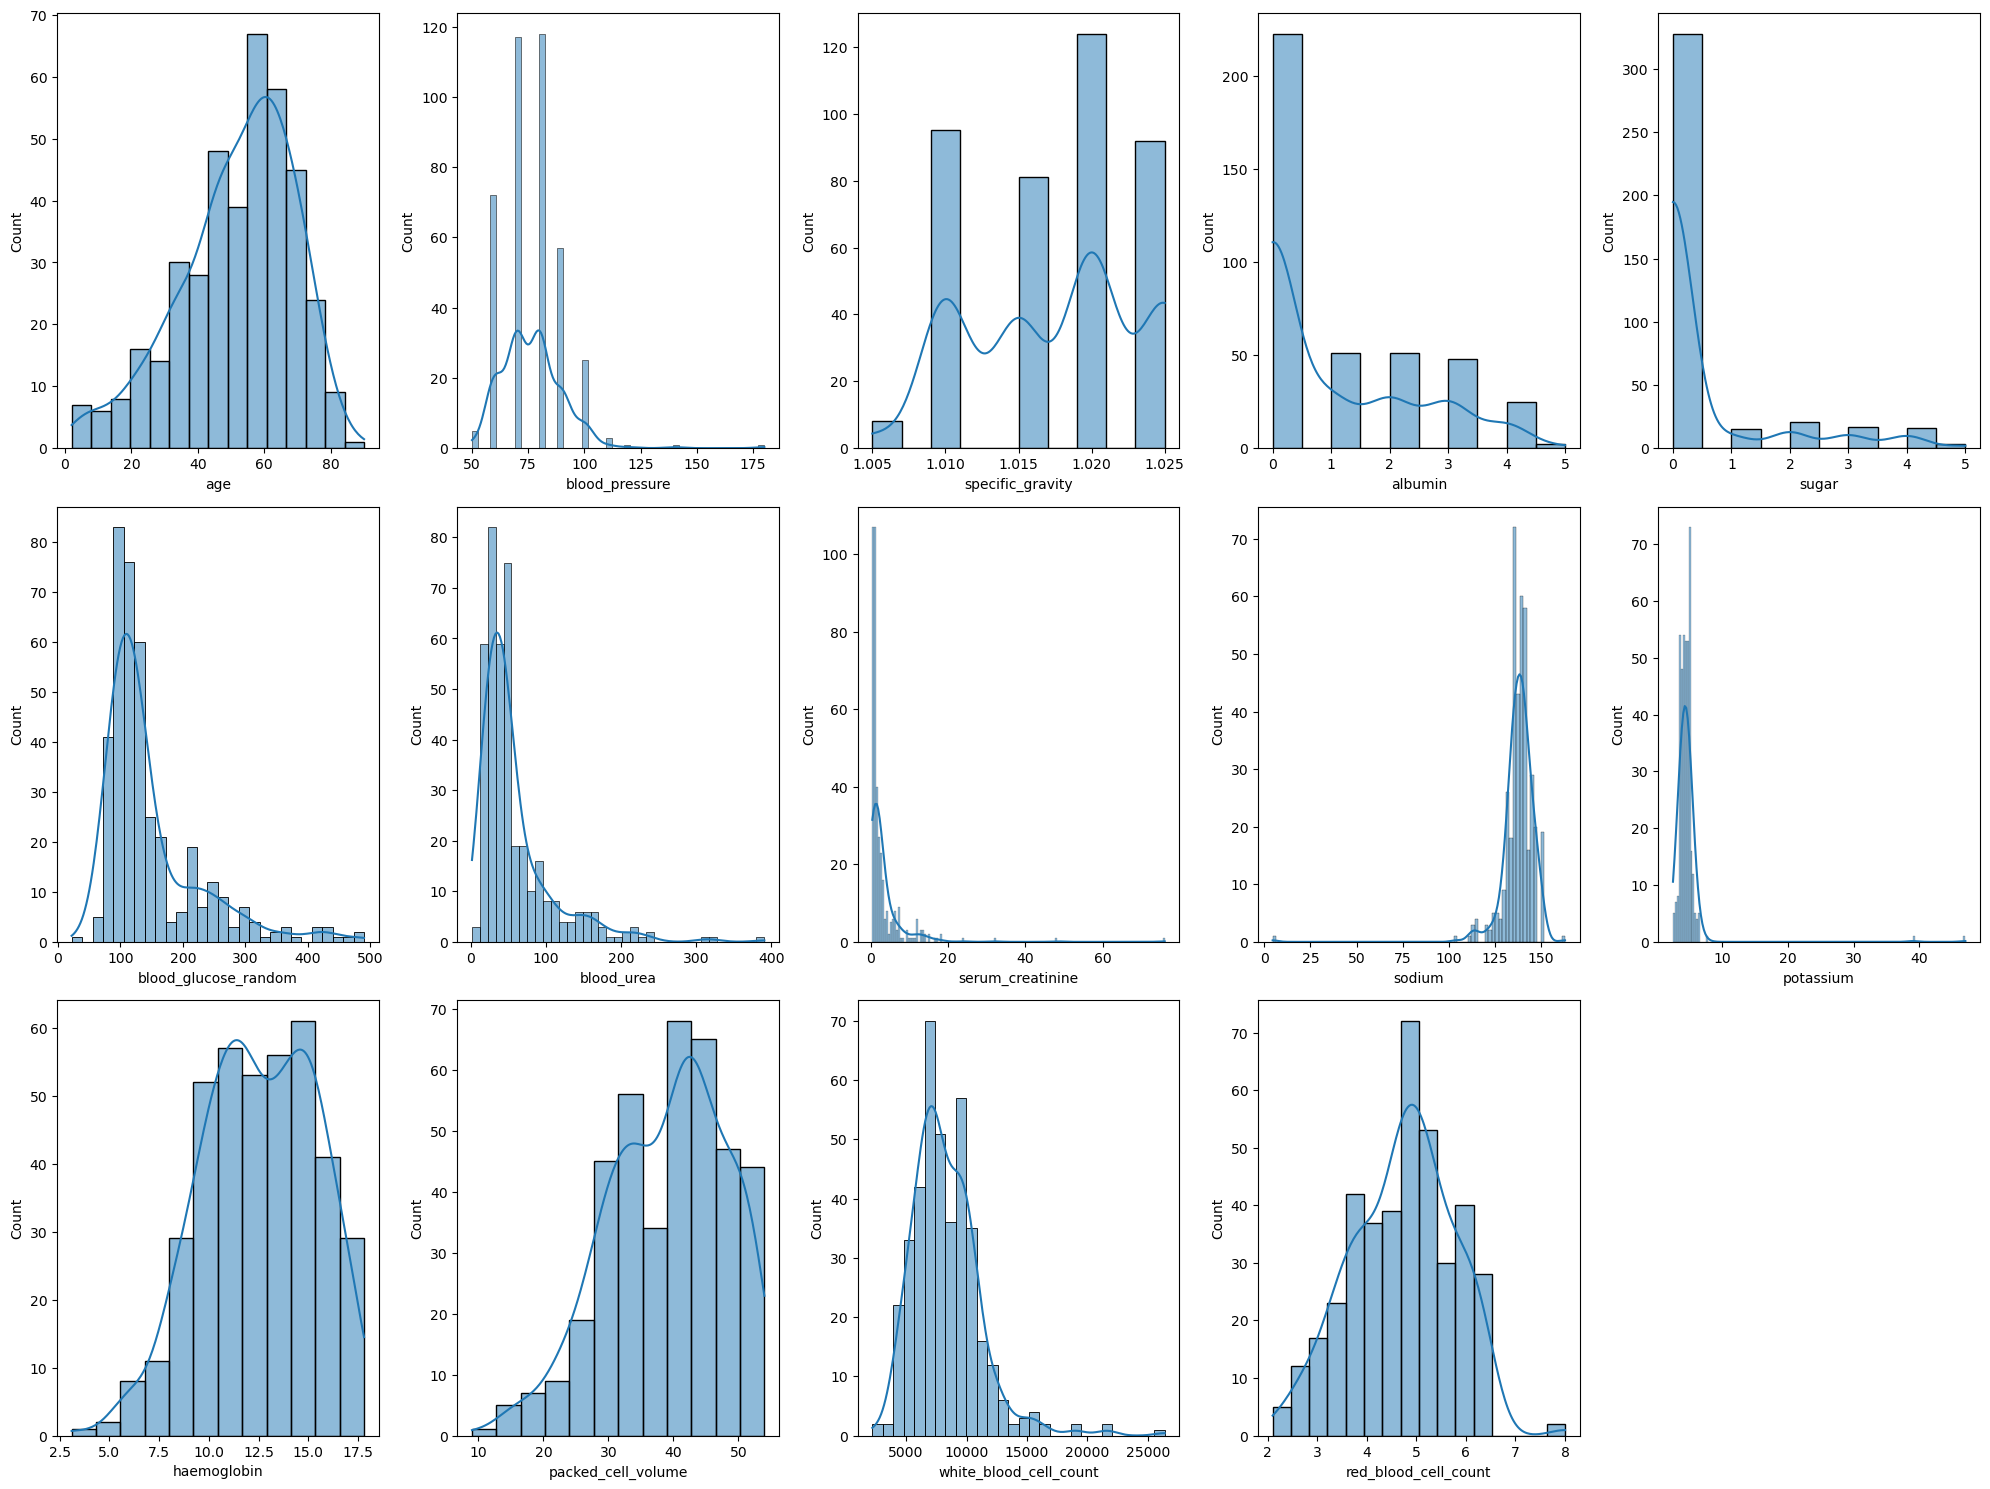

In [31]:
# checking numerical features distribution
Num_fea_path = os.path.join(graphs_dir, 'numerical_feature.png')
plt.figure(figsize = (20, 15))
plotnumber = 1

for column in num_cols:
    if plotnumber <= 14:
        ax = plt.subplot(3, 5, plotnumber)
        sns.histplot(df[column], kde=True)
        plt.xlabel(column)
        
    plotnumber += 1
    
plt.tight_layout()
plt.savefig(Num_fea_path)
plt.show()

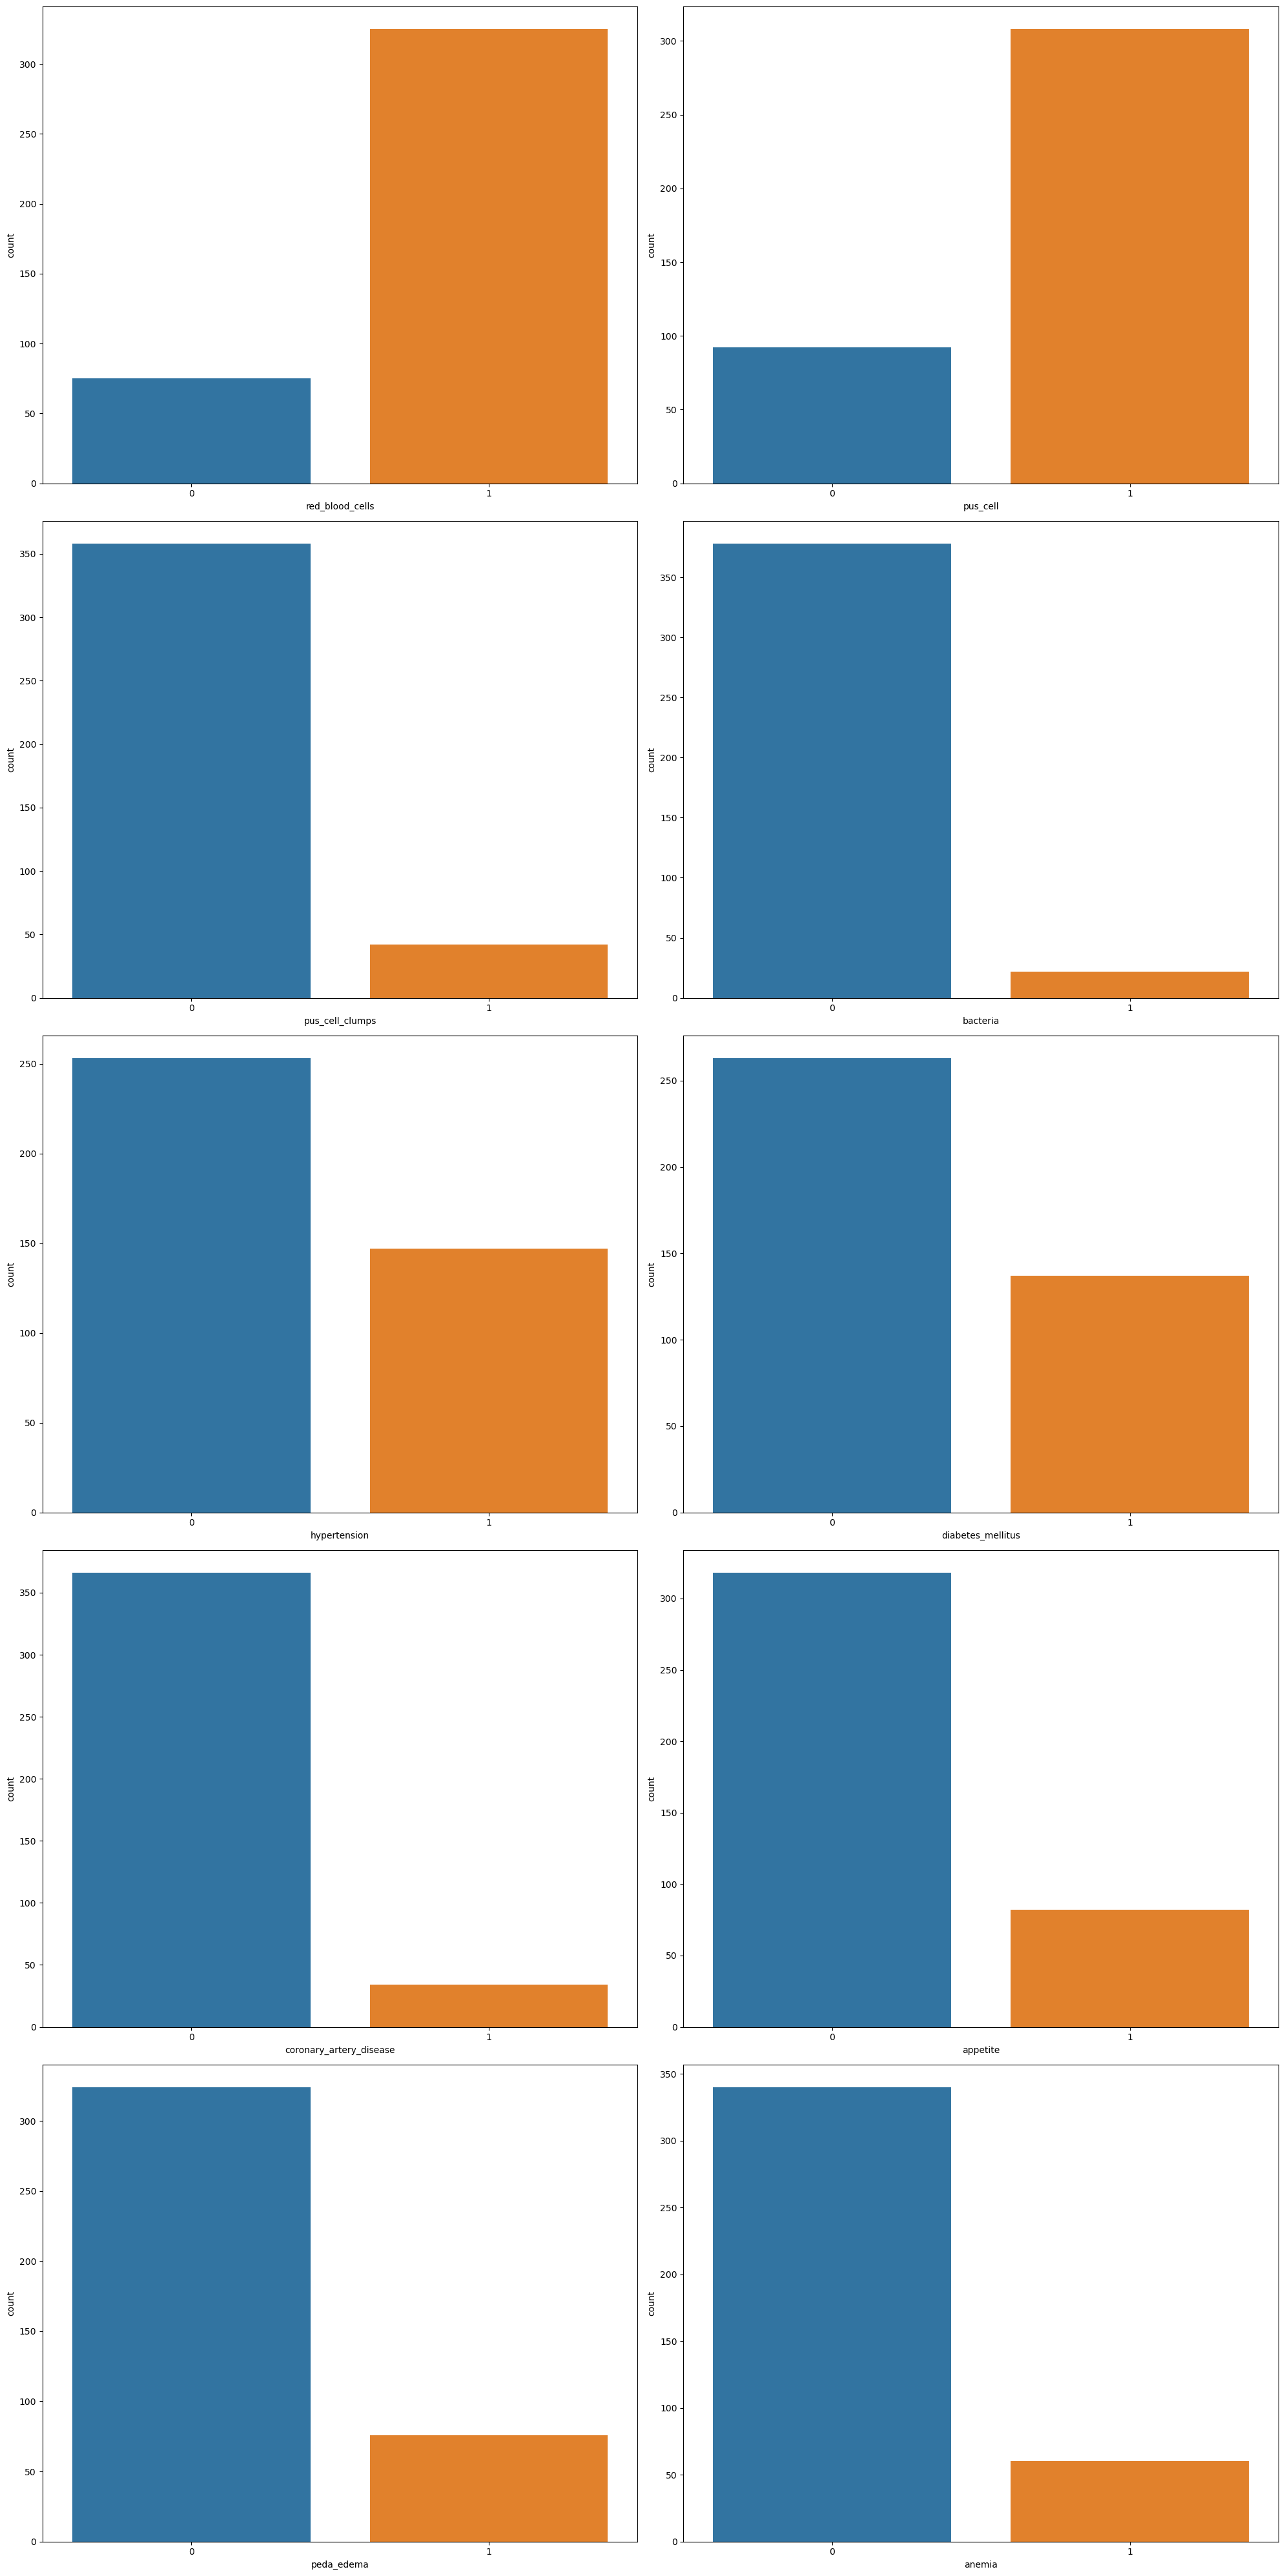

In [32]:
# Checking categorical columns
cat_col_path = os.path.join(graphs_dir, 'categorical_columns.png')
plt.figure(figsize=(20, 40))
plotnumber = 1

for column in cat_cols:
    if plotnumber <= 11:
        ax = plt.subplot(5, 2, plotnumber)
        sns.countplot(data=df, x=column)
        plt.xlabel(column)

    plotnumber += 1

plt.tight_layout()
plt.savefig(cat_col_path)
plt.show()


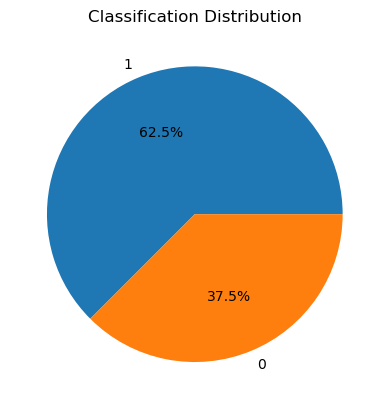

In [33]:
# Checking target class
targetclass_path=os.path.join(graphs_dir, 'target_class.png')
plt.pie(df['class'].value_counts(), labels=df['class'].value_counts().index, autopct='%1.1f%%')
plt.title('Classification Distribution')
plt.savefig(targetclass_path)
plt.show()

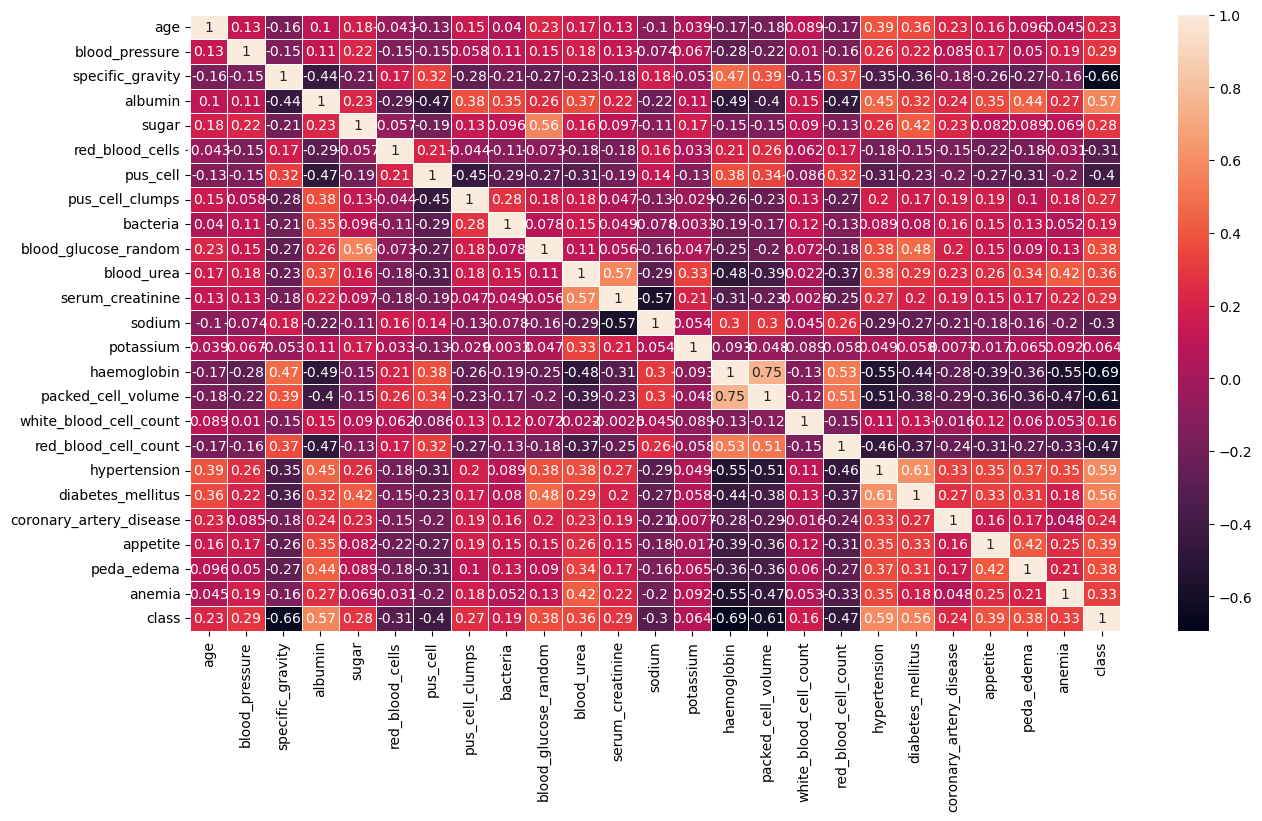

In [34]:
# heatmap of the data
heatmap_path=os.path.join(graphs_dir, 'heatmap.png')
plt.figure(figsize = (15, 8))
sns.heatmap(df.corr(), annot = True, linewidths = 0.5)
plt.savefig(heatmap_path)
plt.show()

In [35]:
# Calculate the correlation list
target_corr = df.corr()['class'].abs().sort_values(ascending=False)[1:]
print(target_corr)

haemoglobin                0.694301
specific_gravity           0.656041
packed_cell_volume         0.605343
hypertension               0.590438
albumin                    0.570918
diabetes_mellitus          0.559060
red_blood_cell_count       0.469733
pus_cell                   0.398803
appetite                   0.393341
blood_glucose_random       0.376085
peda_edema                 0.375154
blood_urea                 0.360251
anemia                     0.325396
red_blood_cells            0.305952
sodium                     0.304305
serum_creatinine           0.288725
blood_pressure             0.287229
sugar                      0.278942
pus_cell_clumps            0.265313
coronary_artery_disease    0.236088
age                        0.227128
bacteria                   0.186871
white_blood_cell_count     0.162924
potassium                  0.064282
Name: class, dtype: float64


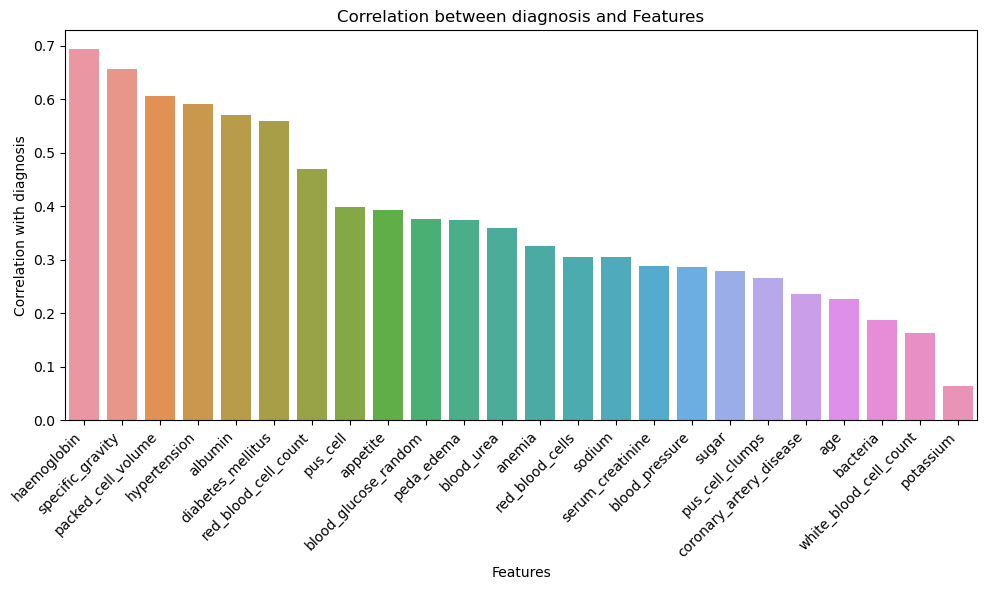

In [36]:
# Create a bar chart to visualize the correlations
correlations_path=os.path.join(graphs_dir, 'correlation.png')
plt.figure(figsize=(10, 6))
sns.barplot(x=target_corr.index, y=target_corr.values)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Features')
plt.ylabel('Correlation with diagnosis')
plt.title('Correlation between diagnosis and Features')
plt.tight_layout()
plt.savefig(correlations_path)
plt.show()

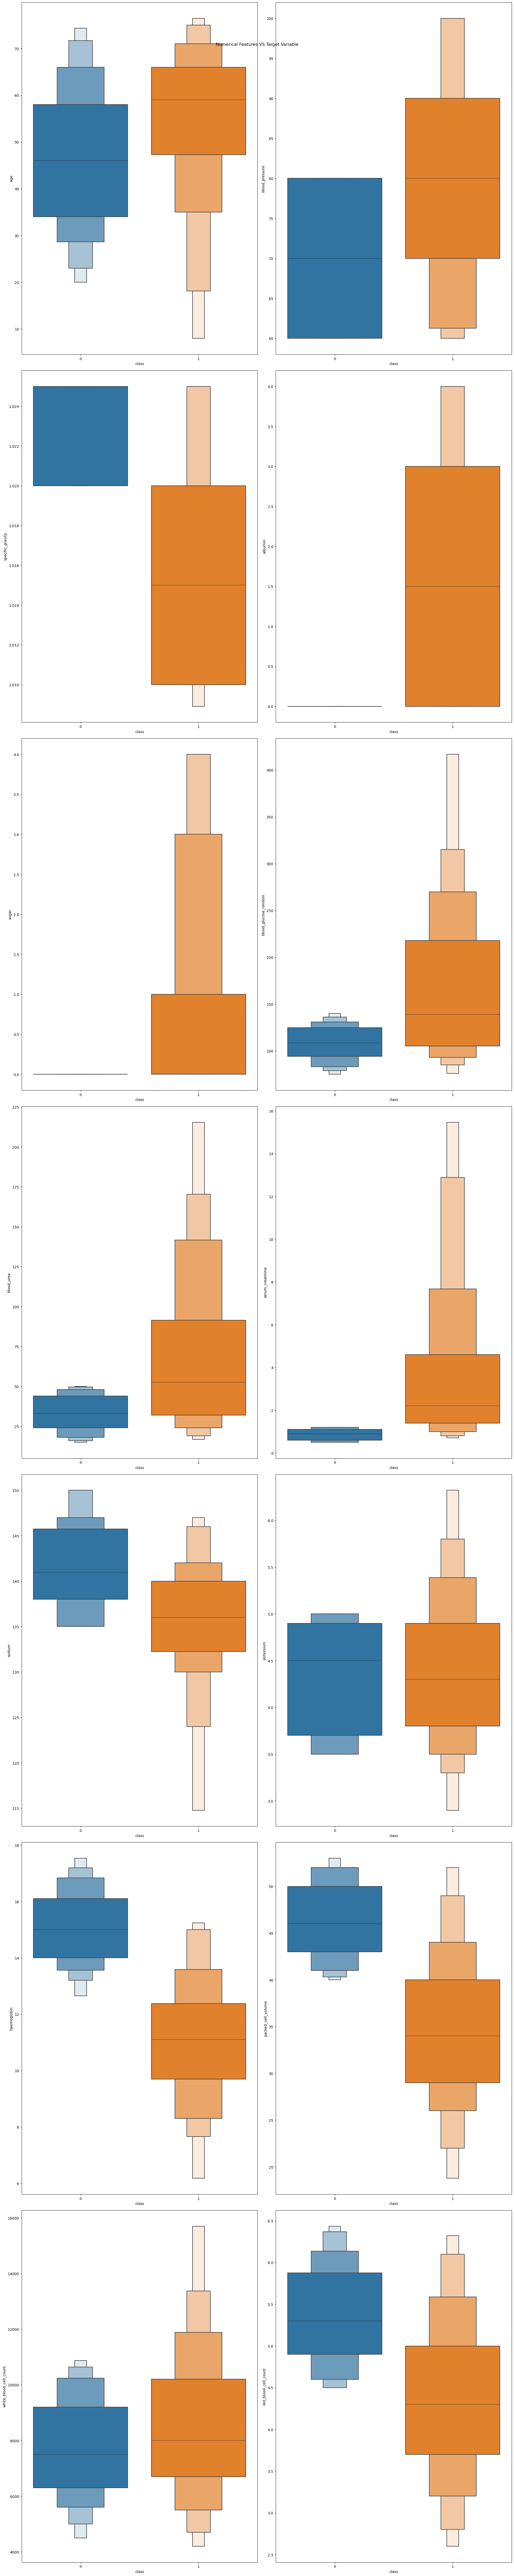

In [37]:
# Creating a boxen plot to show features against the target
n_rows, n_cols = (7,2)

boxen_plot = os.path.join(graphs_dir, 'boxen_plot.png')

figure, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize = (20, 100))
figure.suptitle('Numerical Features VS Target Variable')

for index, column in enumerate(num_cols[:-1]):
    
    i,j = (index // n_cols), (index % n_cols)
    bp=sns.boxenplot(y=column, x='class', data=df, ax=axes[i,j], showfliers=False)
    axes[i,j].set_xlabel(axes[i,j].get_xlabel())
    axes[i,j].set_ylabel(column)
    axes[i,j].set_xticklabels(axes[i,j].get_xticklabels())
plt.tight_layout()
plt.savefig(boxen_plot)
plt.show()

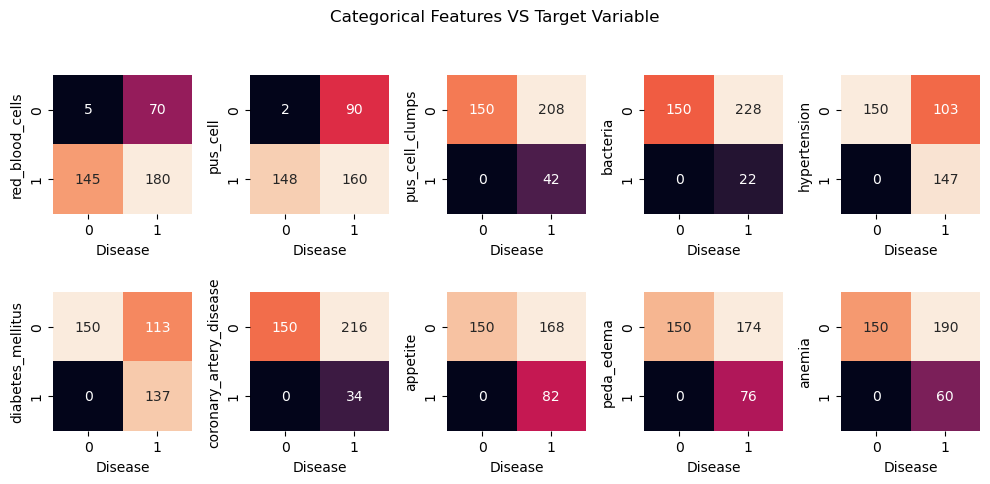

In [38]:
n_rows, n_cols = (2,5)
figure, axes = plt.subplots(nrows=n_rows, ncols=n_cols,figsize=(10, 5))
figure.suptitle('Categorical Features VS Target Variable')
cat_vs_tar_var= os.path.join(graphs_dir, 'cat cols vs target var.png')
for index, column in enumerate(cat_cols):
    i,j = (index // n_cols), (index % n_cols)
    sns.heatmap(pd.crosstab(df[column], df['class']), ax=axes[i,j], square='True', cbar=False, annot=True, fmt='d')
        
    axes[i,j].set_xlabel("Disease")
    axes[i,j].set_ylabel(column)
    
plt.tight_layout()
plt.savefig(cat_vs_tar_var)
plt.show()

In [39]:
#Modelling

In [40]:
base_dir=r"C:\Users\Tharunraj_S\Desktop\Mini_project\Codes\ML logs copy\models"

In [41]:
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.metrics import classification_report

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

def print_score(clf, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=True):
    pred = None  
    if train:
        pred = clf.predict(X_train)
        train_accuracy = accuracy_score(y_train, pred) * 100
        train_roc_auc = roc_auc_score(y_train, y_train_prob) * 100
        
        # ROC Curve for Train Set
        fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
        roc_auc_train = auc(fpr_train, tpr_train)
        plt.figure(figsize=(8, 6))
        plt.plot(fpr_train, tpr_train, color='blue', lw=2, label='ROC curve (area = %0.2f)' % roc_auc_train)
        plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Receiver Operating Characteristic (ROC) - Train Set')
        plt.legend(loc="lower right")
        plt.savefig('ROC Curve Train set')
        plt.show()

        train_results = {
            "Accuracy Score": train_accuracy,
            "ROC AUC Score": train_roc_auc,
            "Confusion Matrix": confusion_matrix(y_train, pred).tolist()
        }
        save_results_to_csv(train_results, "Train_Results.csv")

        print("Train Result:\n================================================")
        print(f"Accuracy Score: {train_accuracy:.2f}%")
        print("_______________________________________________")
        print(f"ROC AUC Score: {train_roc_auc:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{classification_report(y_train, pred)}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {train_results['Confusion Matrix']}\n")
        plt.figure(figsize=(10, 8))
        sns.heatmap(train_results['Confusion Matrix'], annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.title('Confusion Matrix')
        plt.savefig('Confusion Matrix Train set')
        plt.show()
        return train_accuracy, train_roc_auc
    
    elif not train:
        pred = clf.predict(X_test)
        test_accuracy = accuracy_score(y_test, pred) * 100
        test_roc_auc = roc_auc_score(y_test, y_test_prob) * 100
        
        # ROC Curve for Test Set
        fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
        roc_auc_test = auc(fpr_test, tpr_test)
        plt.figure(figsize=(8, 6))
        plt.plot(fpr_test, tpr_test, color='blue', lw=2, label='ROC curve (area = %0.2f)' % roc_auc_test)
        plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Receiver Operating Characteristic (ROC) - Test Set')
        plt.legend(loc="lower right")
        plt.savefig('ROC Curve Test set')
        plt.show()

        test_results = {
            "Accuracy Score": test_accuracy,
            "ROC AUC Score": test_roc_auc,
            "Confusion Matrix": confusion_matrix(y_test, pred).tolist()
        }
        save_results_to_csv(test_results, "Test_Results.csv")

        print("Test Result:\n================================================")
        print(f"Accuracy Score: {test_accuracy:.2f}%")
        print("_______________________________________________")
        print(f"ROC AUC Score: {test_roc_auc:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{classification_report(y_test, pred)}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {test_results['Confusion Matrix']}\n")
        plt.figure(figsize=(10, 8))
        sns.heatmap(test_results['Confusion Matrix'], annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.title('Confusion Matrix')
        plt.savefig('Confusion Matrix Test set')
        plt.show()
        return test_accuracy, test_roc_auc


In [42]:
def create_dir(subdir):
    if not os.path.exists(subdir):
        os.makedirs(os.path.join(base_dir, subdir), exist_ok=True)
    os.chdir(os.path.join(base_dir, subdir))
    updated_dir = os.getcwd()
    print("Saving in directory:", updated_dir)
    
def save_results_to_csv(results, filename):
    df = pd.DataFrame(results)
    df.to_csv(filename, index=False)

In [43]:
#SPLITTING AND SCALING

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV


X = df.drop("class", axis=1)
y = df["class"]

print(f"'X' shape: {X.shape}")
print(f"'y' shape: {y.shape}")

pipeline = Pipeline([
    ('min_max_scaler', MinMaxScaler()),
    ('std_scaler', StandardScaler())])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle = True, random_state=1)
X_train = pipeline.fit_transform(X_train)
X_test = pipeline.transform(X_test)

'X' shape: (400, 24)
'y' shape: (400,)


In [45]:
len(y_train)

320

# LOGISTIC REGRESSION

Saving in directory: C:\Users\Tharunraj_S\Desktop\Mini_project\Codes\ML logs copy\models\Logistic Regression
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'C': 0.0022066368741934005, 'penalty': 'l2', 'solver': 'newton-cg'}


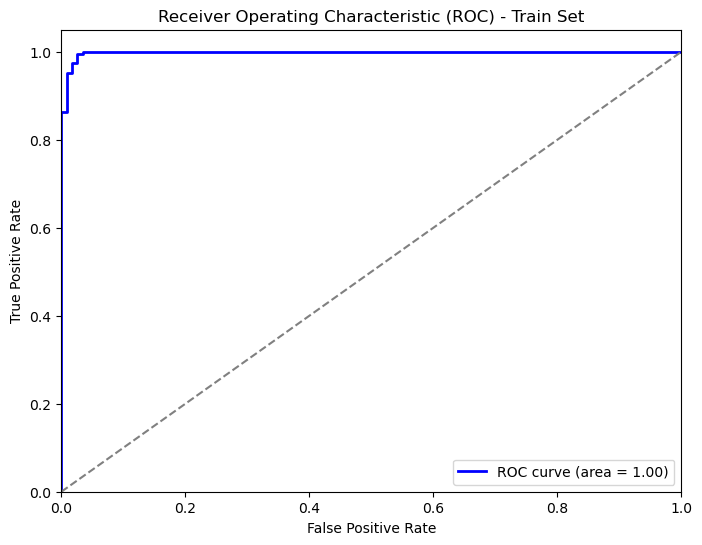

Train Result:
Accuracy Score: 98.44%
_______________________________________________
ROC AUC Score: 99.81%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98       117
           1       0.98      1.00      0.99       203

    accuracy                           0.98       320
   macro avg       0.99      0.98      0.98       320
weighted avg       0.98      0.98      0.98       320

_______________________________________________
Confusion Matrix: 
 [[112, 5], [0, 203]]



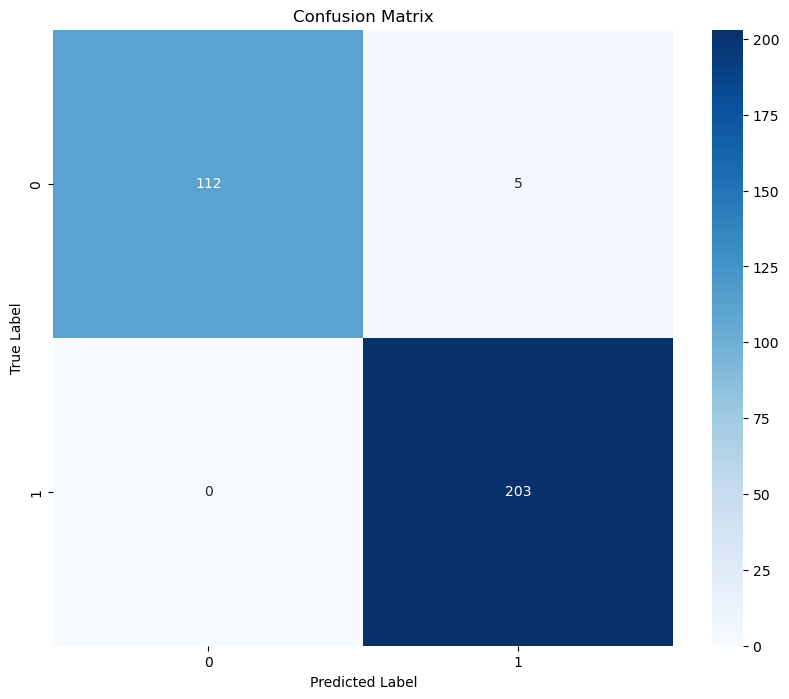

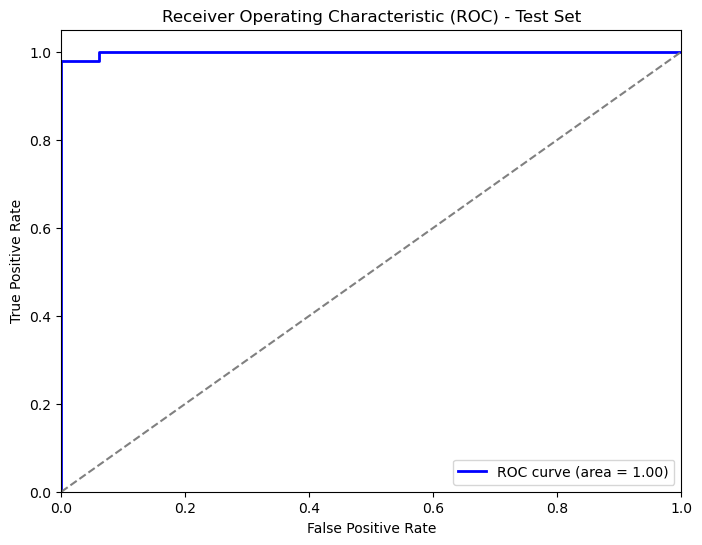

Test Result:
Accuracy Score: 97.50%
_______________________________________________
ROC AUC Score: 99.87%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        33
           1       0.98      0.98      0.98        47

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80

_______________________________________________
Confusion Matrix: 
 [[32, 1], [1, 46]]



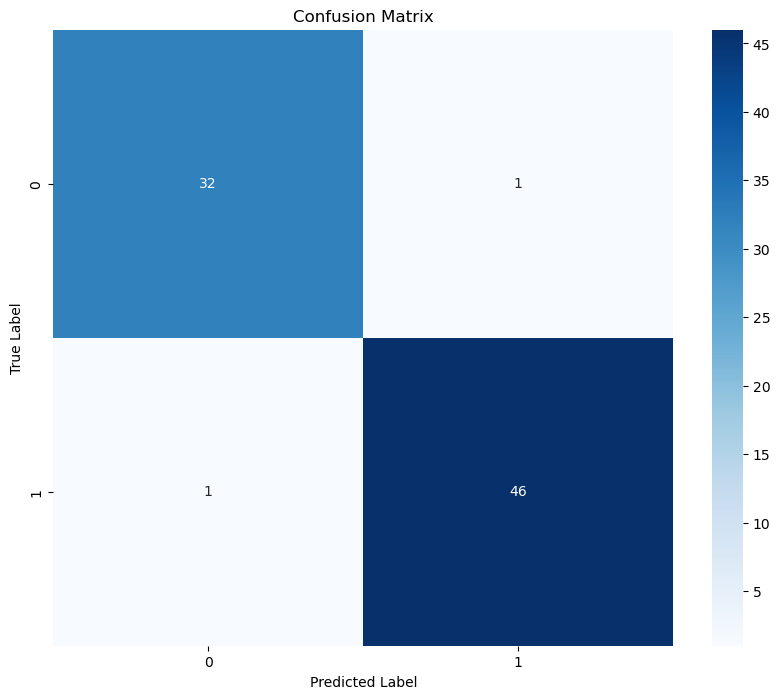

['logistic_regression.pkl']

In [47]:
from scipy.stats import loguniform
from sklearn.linear_model import LogisticRegression

os.chdir(base_dir)
create_dir('Logistic Regression')


param_grid = dict()
param_grid['solver'] = ['newton-cg', 'lbfgs', 'liblinear']
param_grid['penalty'] = ['l2'] #'none', 'l1', 'l2', 'elasticnet'
param_grid['C'] = loguniform.rvs(1e-5, 100, size=10)

grid = GridSearchCV(LogisticRegression(), param_grid, refit=True, verbose=1, cv=5)
LR_model = grid.fit(X_train, y_train).best_estimator_

best_params = grid.best_params_
print(f"Best params: {best_params}")

y_train_prob = LR_model.predict_proba(X_train)[:, 1]
y_test_prob = LR_model.predict_proba(X_test)[:, 1]

print_score(LR_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=True)
lr_acc, lr_ra = print_score(LR_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=False)
joblib.dump(LR_model,'logistic_regression.pkl')



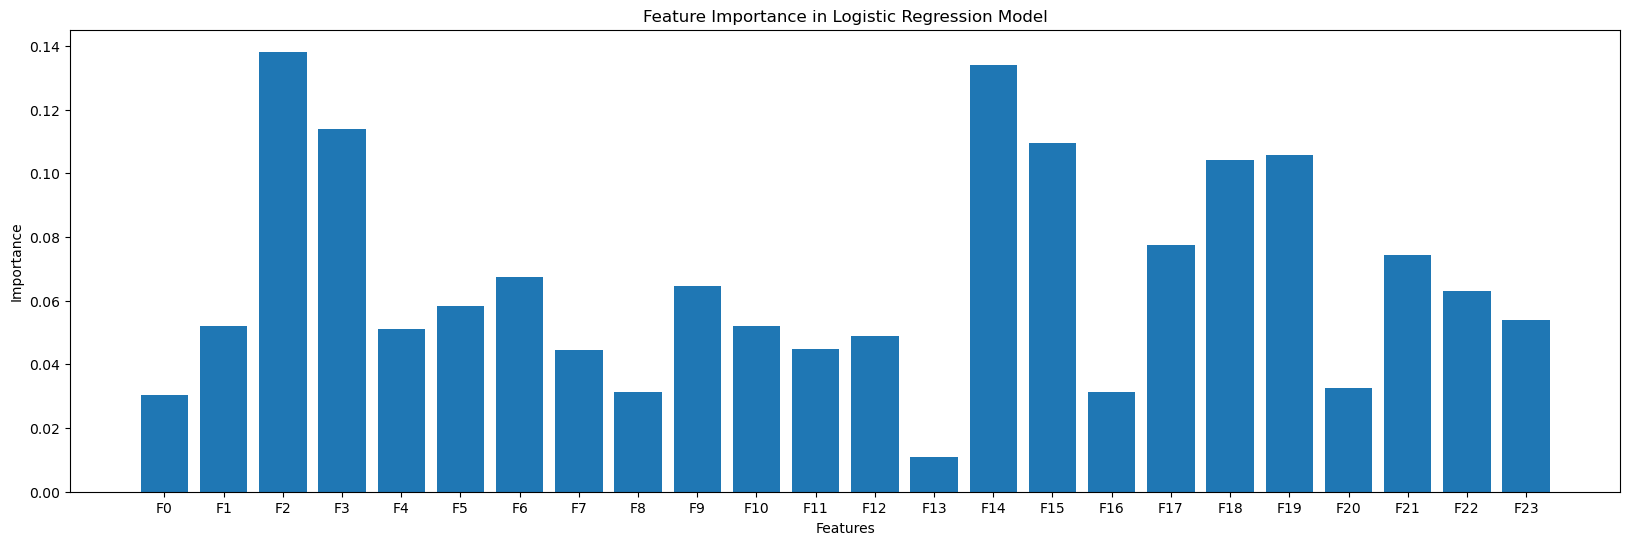

In [49]:
# Assuming you don't have feature names stored elsewhere
feature_names = ["F" + str(i) for i in range(len(LR_model.coef_.ravel()))]
feature_importances = abs(LR_model.coef_.ravel())  # Absolute values
plt.figure(figsize=(20, 6))
plt.bar(feature_names, feature_importances)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Logistic Regression Model")
plt.savefig("Feature Importance in Logistic Regression Model")
plt.show()


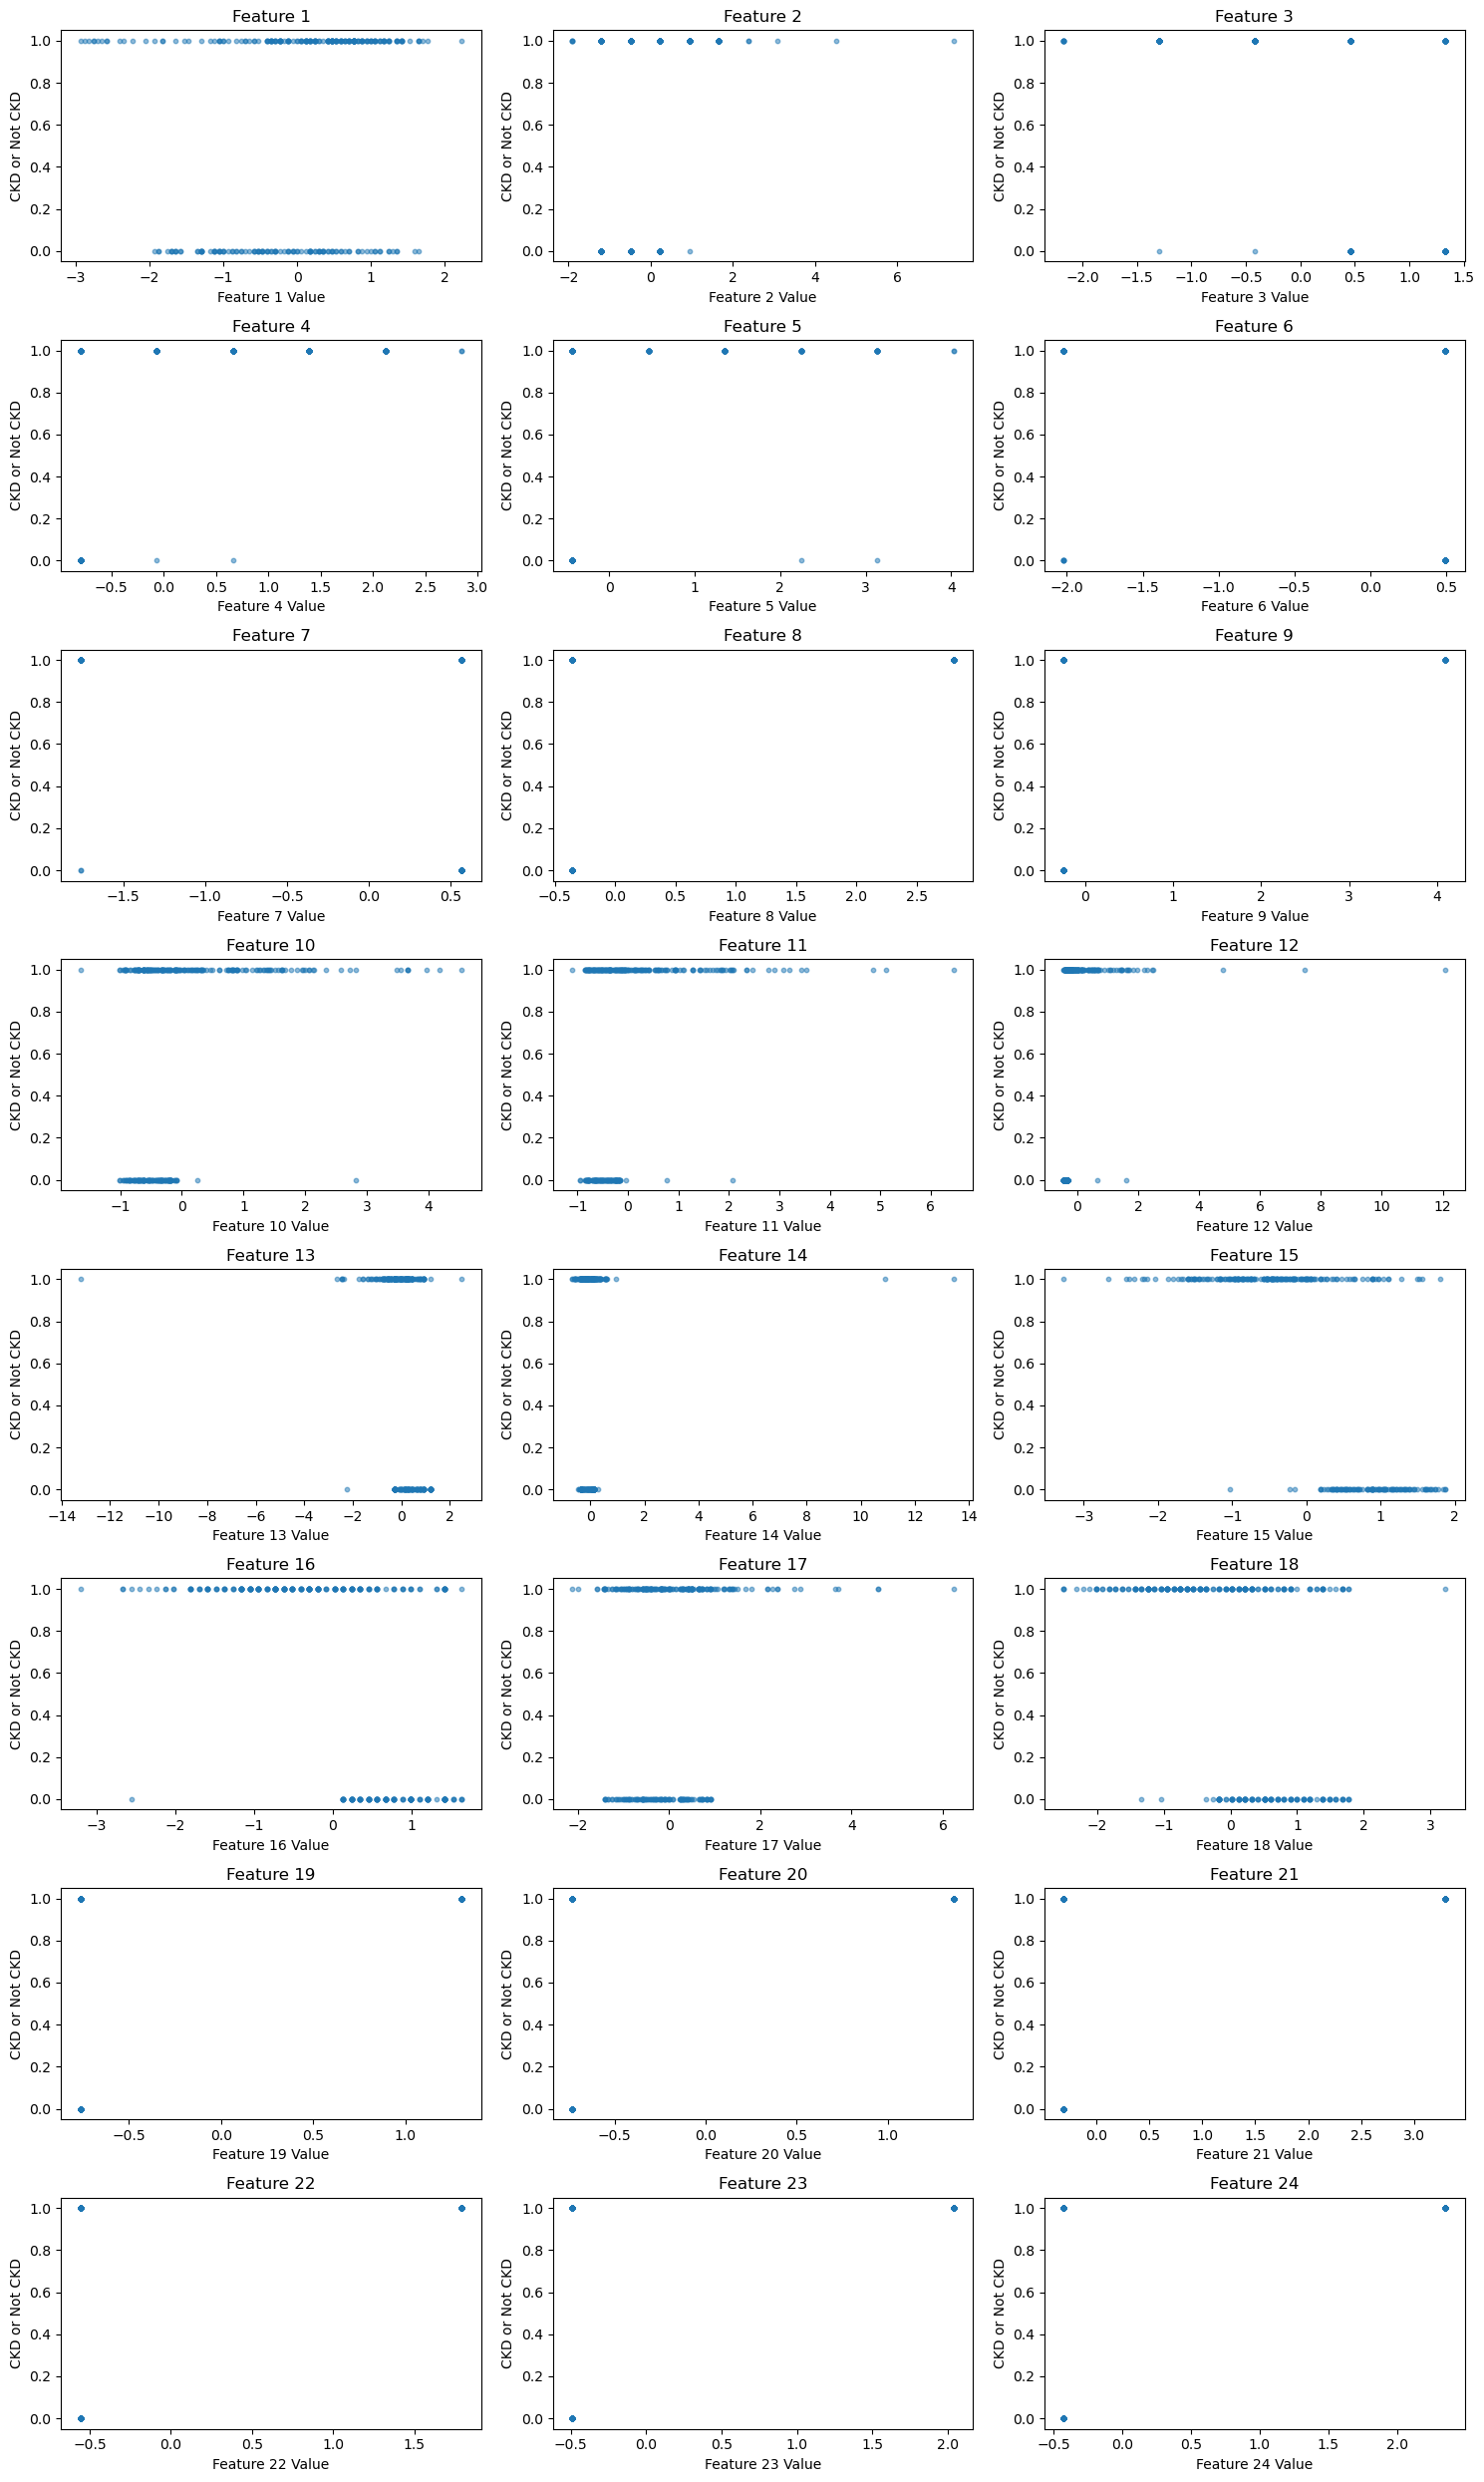

In [50]:
import matplotlib.pyplot as plt

# Define the number of rows and columns for the subplot grid
n_rows = 8  
n_cols = 3  

# Create a subplot grid
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 25))

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot each feature against the target variable
for i, ax in enumerate(axes):
    if i < len(X_train[0]):  # Make sure not to exceed the number of features
        ax.scatter(X_train[:, i], y_train, s=10, alpha=0.5)
        ax.set_title(f'Feature {i+1}')
        ax.set_xlabel(f'Feature {i+1} Value')
        ax.set_ylabel('CKD or Not CKD')

# Adjust layout to prevent overlap of subplots
plt.tight_layout()
plt.savefig('LR features')
plt.show()


In [70]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def visualize_pca(X_train, X_test, y_train, y_test):
    pca = PCA(n_components=2)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    
    plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', alpha=0.7)
    plt.title('PCA - Train Data', fontsize=14)
    plt.xlabel('Principal Component 1', fontsize=12)
    plt.ylabel('Principal Component 2', fontsize=12)
    plt.colorbar(label='Target')

    plt.subplot(1, 2, 2)
    plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='coolwarm', edgecolor='k', alpha=0.7)
    plt.title('PCA - Test Data', fontsize=14)
    plt.xlabel('Principal Component 1', fontsize=12)
    plt.ylabel('Principal Component 2', fontsize=12)
    plt.colorbar(label='Target')

    plt.tight_layout()
    plt.savefig('PCA_visualization.png', dpi=300)
    plt.show()

def visualize_tsne(X_train, X_test, y_train, y_test):
    tsne = TSNE(n_components=2, perplexity=30, n_iter=300)
    X_train_tsne = tsne.fit_transform(X_train)
    X_test_tsne = tsne.fit_transform(X_test)

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.scatter(X_train_tsne[:, 0], X_train_tsne[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', alpha=0.7)
    plt.title('t-SNE - Train Data', fontsize=14)
    plt.xlabel('t-SNE Component 1', fontsize=12)
    plt.ylabel('t-SNE Component 2', fontsize=12)
    plt.colorbar(label='Target')

    plt.subplot(1, 2, 2)
    plt.scatter(X_test_tsne[:, 0], X_test_tsne[:, 1], c=y_test, cmap='coolwarm', edgecolor='k', alpha=0.7)
    plt.title('t-SNE - Test Data', fontsize=14)
    plt.xlabel('t-SNE Component 1', fontsize=12)
    plt.ylabel('t-SNE Component 2', fontsize=12)
    plt.colorbar(label='Target')

    plt.tight_layout()
    plt.savefig('tSNE_visualization.png', dpi=300)
    plt.show()


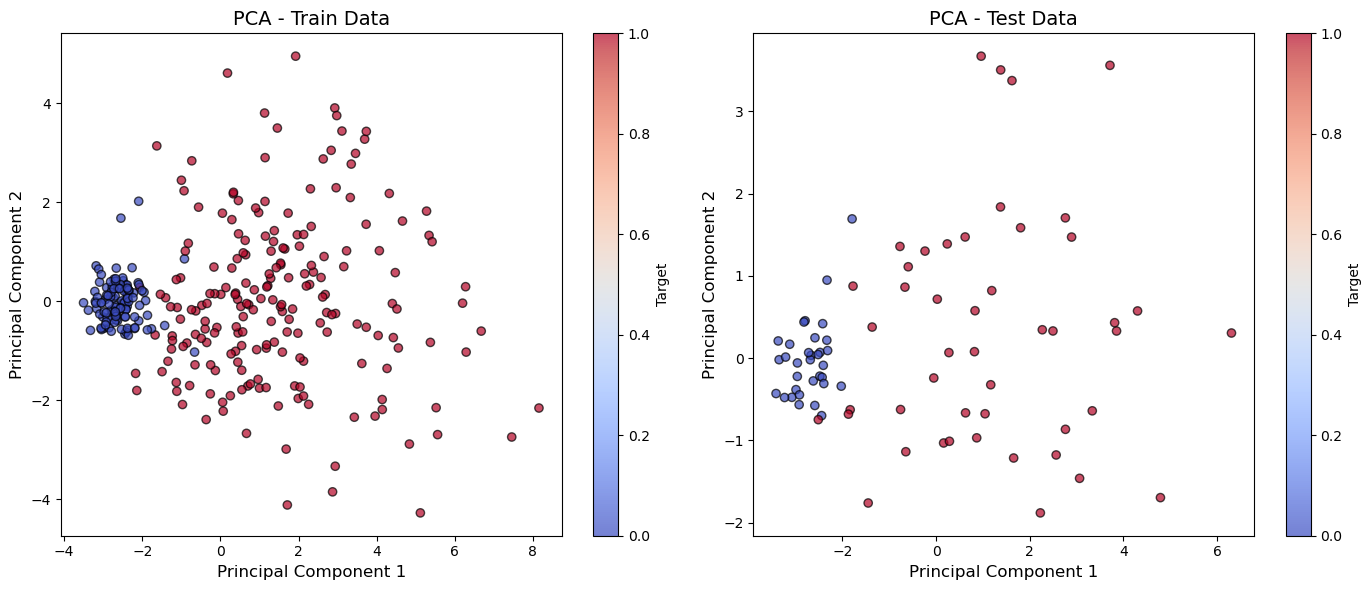

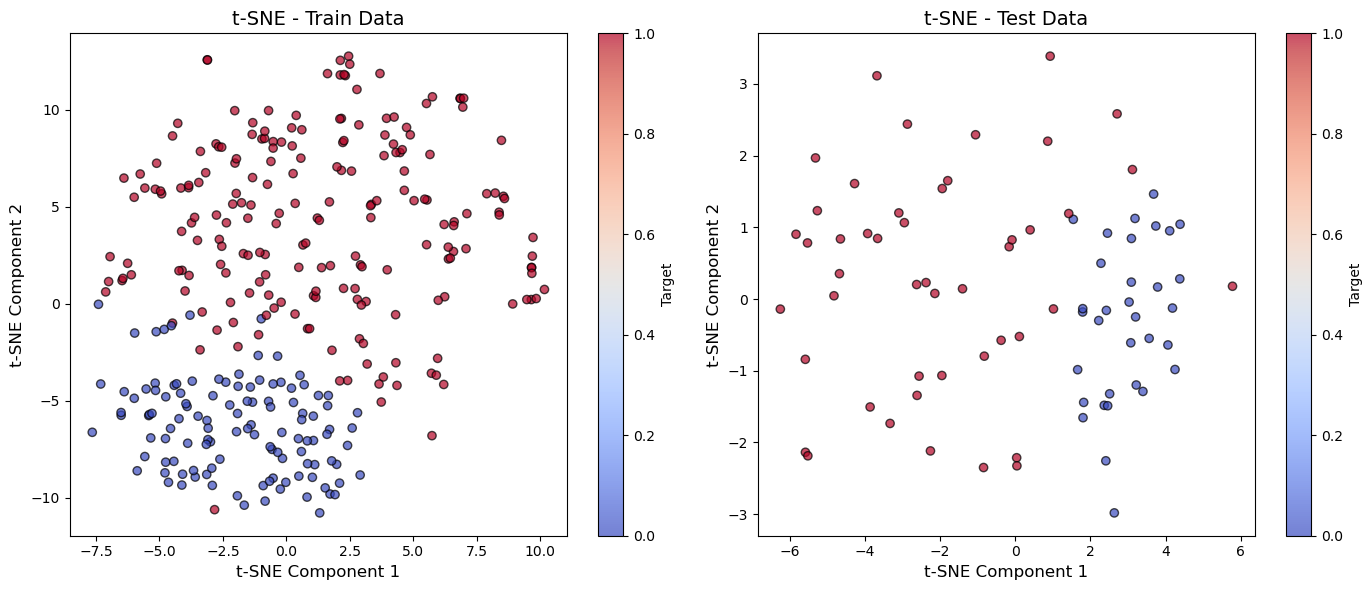

In [71]:
visualize_pca(X_train, X_test, y_train, y_test)
visualize_tsne(X_train, X_test, y_train, y_test)

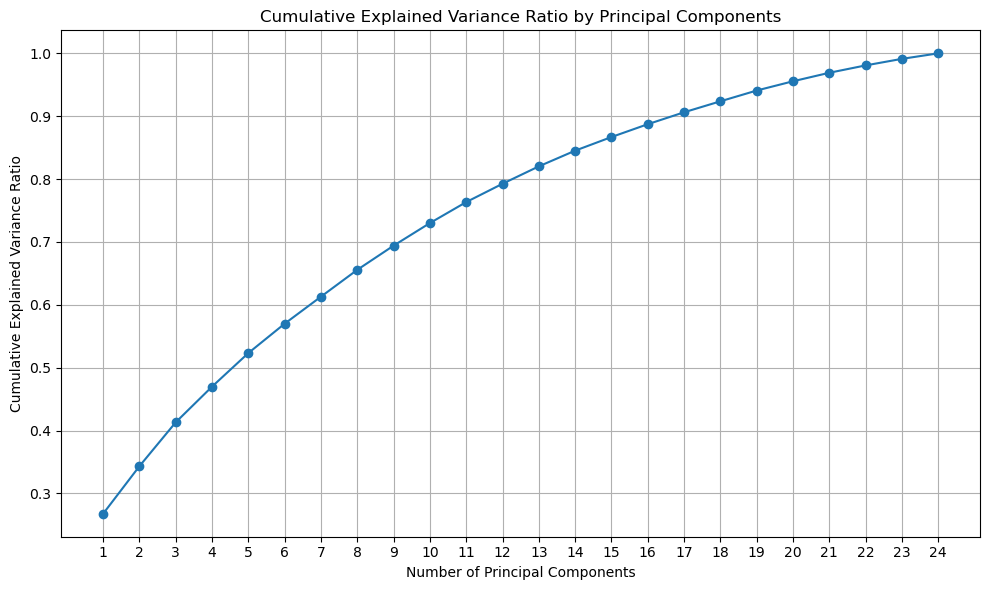

In [55]:
def plot_explained_variance_ratio(X):
    pca = PCA().fit(X)
    explained_variance_ratio = pca.explained_variance_ratio_
    cumulative_explained_variance = np.cumsum(explained_variance_ratio)

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_explained_variance, marker='o', linestyle='-')
    plt.xlabel('Number of Principal Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.title('Cumulative Explained Variance Ratio by Principal Components')
    plt.grid(True)
    plt.xticks(range(1, len(explained_variance_ratio) + 1))
    plt.tight_layout()
    plt.savefig('Cumulative Explained Variance Ratio by Principal Components')
    plt.show()

# Call the function
plot_explained_variance_ratio(X_train)


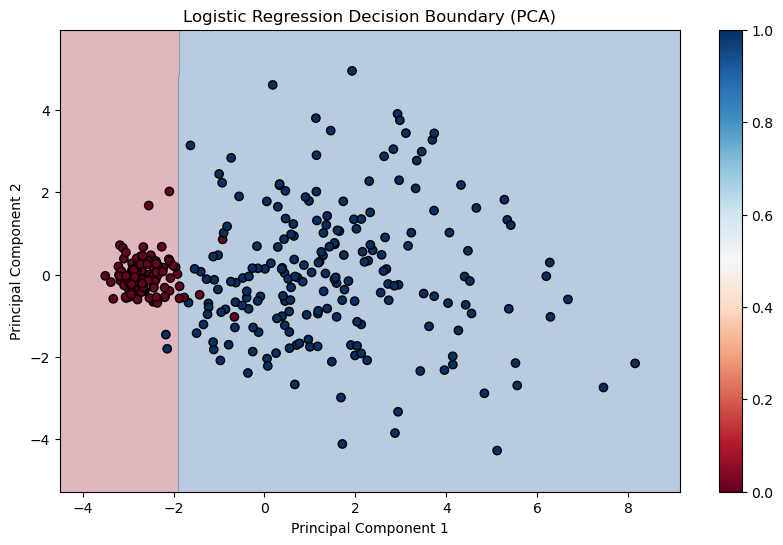

In [64]:
from sklearn.decomposition import PCA

def plot_pca_decision_boundary(X, y, model):
    pca = PCA(n_components=2)  # Set n_components to 4
    X_pca = pca.fit_transform(X)
    model.fit(X_pca, y)  # Train the model on the transformed data after PCA

    h = .02
    x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
    y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdBu, alpha=0.3)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap=plt.cm.RdBu, edgecolor='k')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title('Logistic Regression Decision Boundary (PCA)')
    plt.colorbar()
    plt.savefig('Logistic Regression Decision Boundary (PCA)')
    plt.show()

# Call the function
plot_pca_decision_boundary(X_train, y_train, LR_model)


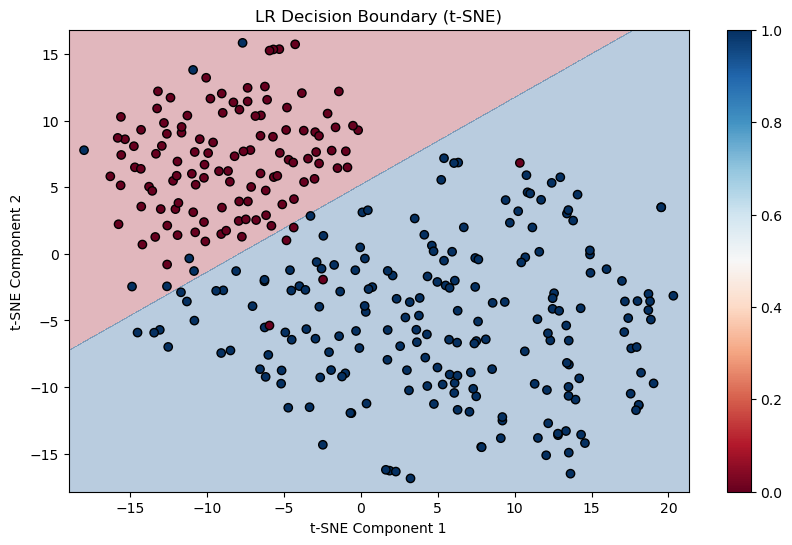

In [65]:
from sklearn.manifold import TSNE

def plot_knn_tsne_decision_boundary(X, y, model):
    tsne = TSNE(n_components=2, random_state=42)
    X_tsne = tsne.fit_transform(X)
    model.fit(X_tsne, y)

    h = .02
    x_min, x_max = X_tsne[:, 0].min() - 1, X_tsne[:, 0].max() + 1
    y_min, y_max = X_tsne[:, 1].min() - 1, X_tsne[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdBu, alpha=0.3)
    plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap=plt.cm.RdBu, edgecolor='k')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.title('LR Decision Boundary (t-SNE)')
    plt.colorbar()
    plt.savefig('LR Decision Boundary (t-SNE)')
    plt.show()

# Call the function
plot_knn_tsne_decision_boundary(X_train, y_train, LR_model)


# KNN

Saving in directory: C:\Users\Tharunraj_S\Desktop\Mini_project\Codes\ML logs copy\models\KNeighborsClassifier
Fitting 5 folds for each of 300 candidates, totalling 1500 fits
Best params: {'algorithm': 'ball_tree', 'leaf_size': 1, 'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}


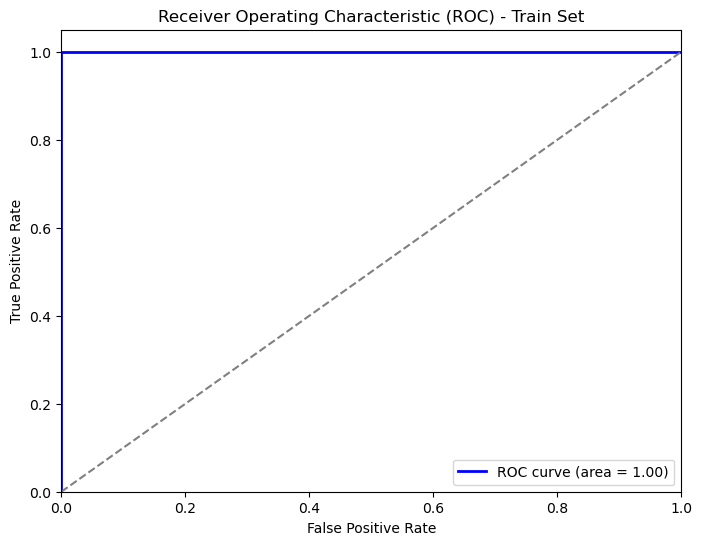

Train Result:
Accuracy Score: 100.00%
_______________________________________________
ROC AUC Score: 100.00%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       117
           1       1.00      1.00      1.00       203

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320

_______________________________________________
Confusion Matrix: 
 [[117, 0], [0, 203]]



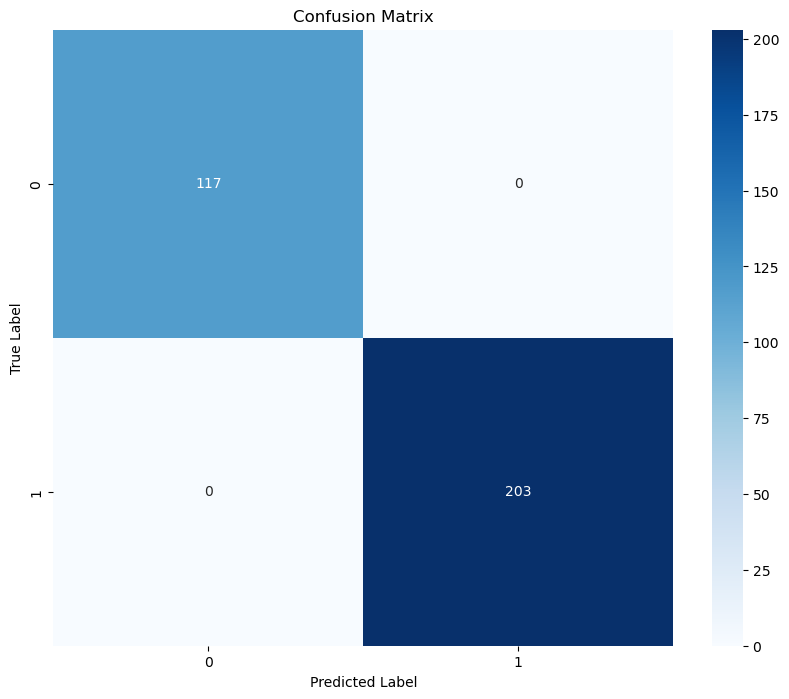

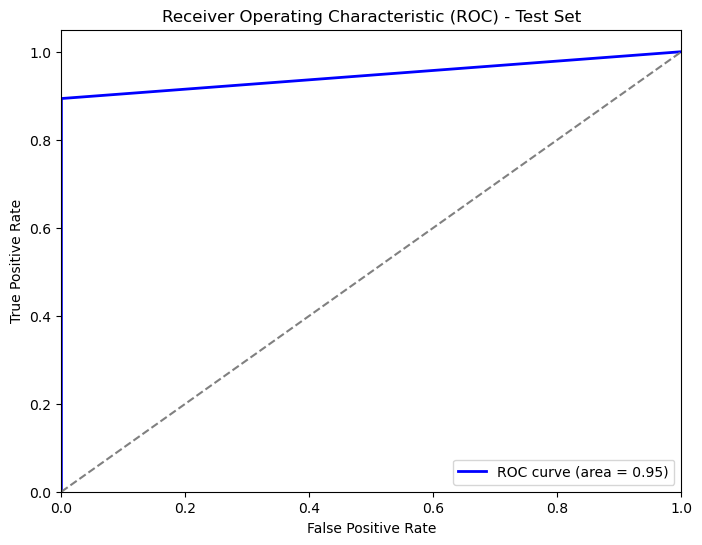

Test Result:
Accuracy Score: 93.75%
_______________________________________________
ROC AUC Score: 94.68%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.87      1.00      0.93        33
           1       1.00      0.89      0.94        47

    accuracy                           0.94        80
   macro avg       0.93      0.95      0.94        80
weighted avg       0.95      0.94      0.94        80

_______________________________________________
Confusion Matrix: 
 [[33, 0], [5, 42]]



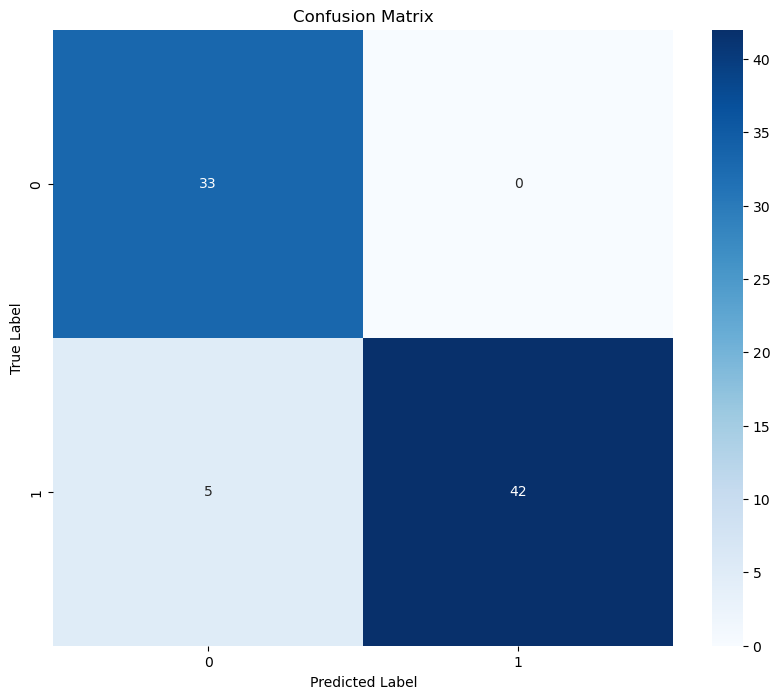

['KNeighborsClassifier.pkl']

In [73]:
from sklearn.neighbors import KNeighborsClassifier

os.chdir(base_dir)
create_dir('KNeighborsClassifier')

param_grid = {"n_neighbors": [i for i in range(1, 50, 10)],
             "weights": ["uniform", "distance"],
             "algorithm": ["ball_tree", "kd_tree", "brute"],
             "leaf_size": [i for i in range(1, 50, 10)],
             "p": [1,2]}

grid = GridSearchCV(KNeighborsClassifier(), param_grid, refit=True, verbose=1, cv=5)
KNN_model = grid.fit(X_train, y_train).best_estimator_

best_params = grid.best_params_
print(f"Best params: {best_params}")

y_train_prob = KNN_model.predict_proba(X_train)[:, 1]
y_test_prob = KNN_model.predict_proba(X_test)[:, 1]

print_score(KNN_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=True)
knn_acc, knn_ra =print_score(KNN_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=False)
joblib.dump(KNN_model,'KNeighborsClassifier.pkl')



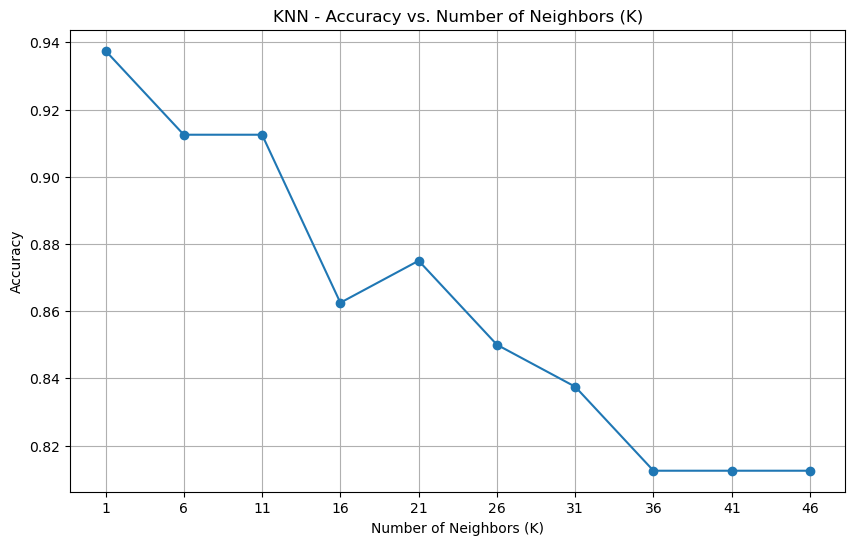

In [74]:
# KNN Graph - Accuracy vs. K
k_values = [i for i in range(1, 50, 5)]
accuracies = []
for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o')
plt.title('KNN - Accuracy vs. Number of Neighbors (K)')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.savefig('KNN_Accuracy_vs_K.png')
plt.show()

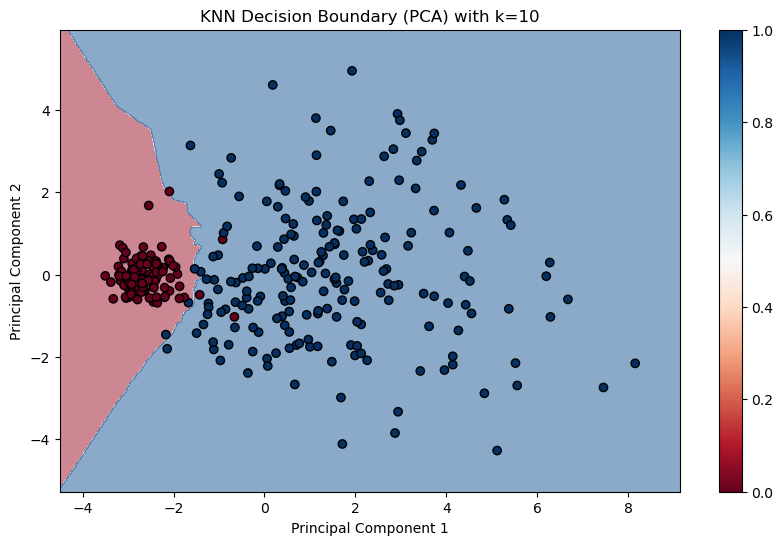

In [81]:
from sklearn.neighbors import KNeighborsClassifier

def plot_knn_decision_boundary(X, y, n_neighbors=5):
    pca = PCA(n_components=2)  
    X_pca = pca.fit_transform(X)
    
    # Create and fit KNN model
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X_pca, y)  

    # Plot decision boundary
    h = .02
    x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
    y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdBu, alpha=0.5)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap=plt.cm.RdBu, edgecolor='k')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'KNN Decision Boundary (PCA) with k={n_neighbors}')
    plt.colorbar()
    plt.savefig(f'KNN_Decision_Boundary_PCA_k={n_neighbors}.png', dpi=300)
    plt.show()

# Assuming you have X_train, X_test, y_train, and y_test ready
plot_knn_decision_boundary(X_train, y_train, n_neighbors=10)  # You can adjust n_neighbors as needed


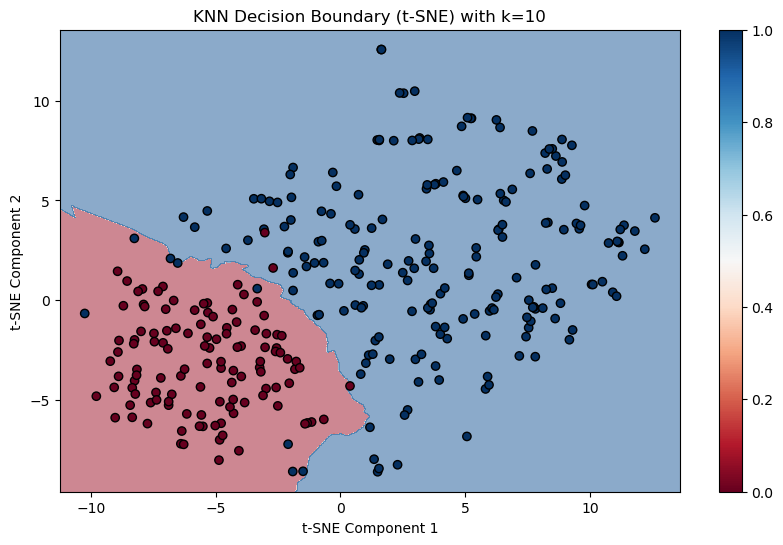

In [82]:
from sklearn.manifold import TSNE

def plot_knn_decision_boundary_tsne(X, y, n_neighbors=5):
    tsne = TSNE(n_components=2, perplexity=30, n_iter=300)
    X_tsne = tsne.fit_transform(X)
    
    # Create and fit KNN model
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X_tsne, y)  

    # Plot decision boundary
    h = .02
    x_min, x_max = X_tsne[:, 0].min() - 1, X_tsne[:, 0].max() + 1
    y_min, y_max = X_tsne[:, 1].min() - 1, X_tsne[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdBu, alpha=0.5)
    plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap=plt.cm.RdBu, edgecolor='k')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.title(f'KNN Decision Boundary (t-SNE) with k={n_neighbors}')
    plt.colorbar()
    plt.savefig(f'KNN_Decision_Boundary_tSNE_k={n_neighbors}.png', dpi=300)
    plt.show()

# Assuming you have X_train, X_test, y_train, and y_test ready
plot_knn_decision_boundary_tsne(X_train, y_train, n_neighbors=10)  # You can adjust n_neighbors as needed


# DECISION TREE

Saving in directory: C:\Users\Tharunraj_S\Desktop\Mini_project\Codes\ML logs copy\models\DecisionTreeClassifier
Fitting 5 folds for each of 210 candidates, totalling 1050 fits
Best params: {'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 5}


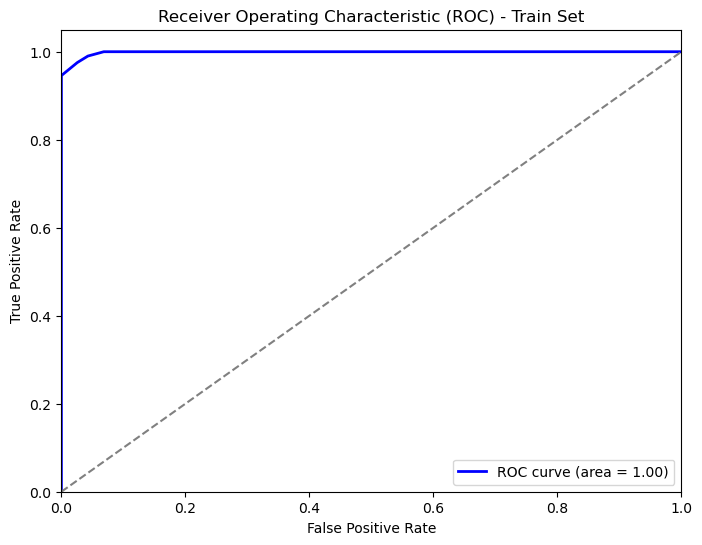

Train Result:
Accuracy Score: 97.81%
_______________________________________________
ROC AUC Score: 99.86%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       117
           1       0.98      0.99      0.98       203

    accuracy                           0.98       320
   macro avg       0.98      0.97      0.98       320
weighted avg       0.98      0.98      0.98       320

_______________________________________________
Confusion Matrix: 
 [[112, 5], [2, 201]]



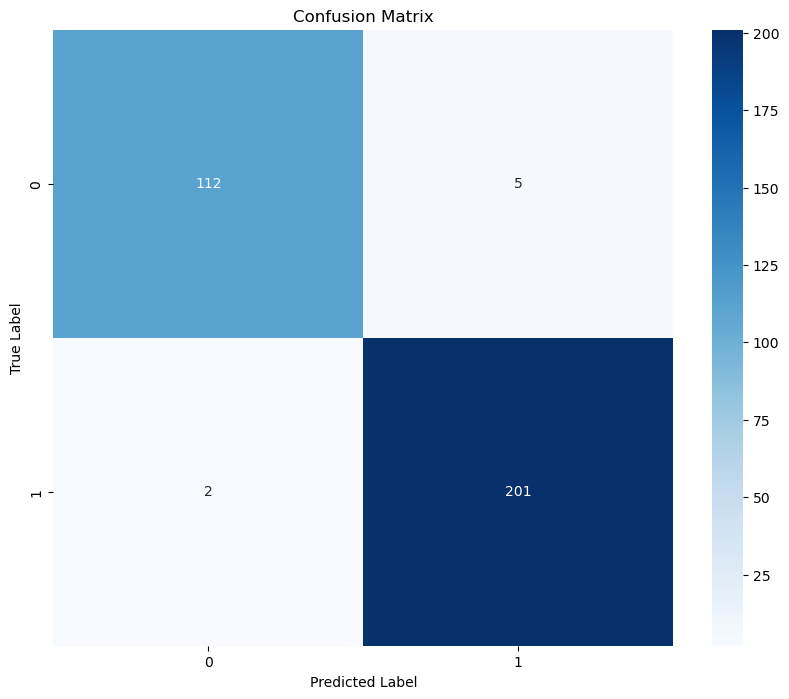

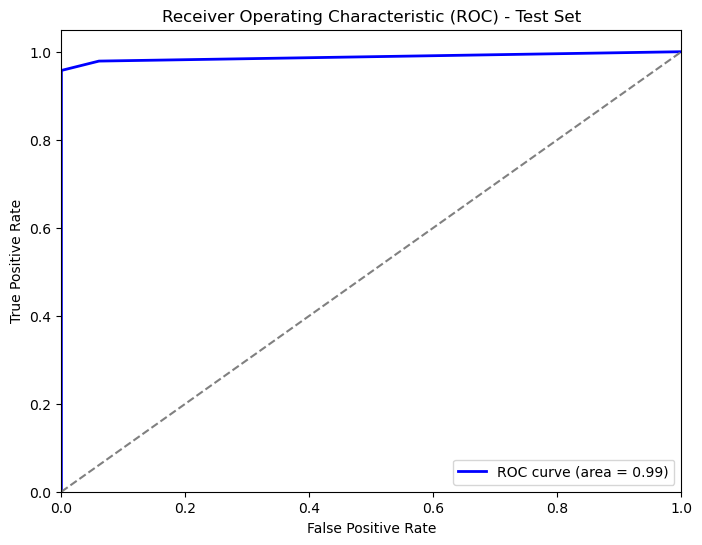

Test Result:
Accuracy Score: 96.25%
_______________________________________________
ROC AUC Score: 98.81%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95        33
           1       0.96      0.98      0.97        47

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80

_______________________________________________
Confusion Matrix: 
 [[31, 2], [1, 46]]



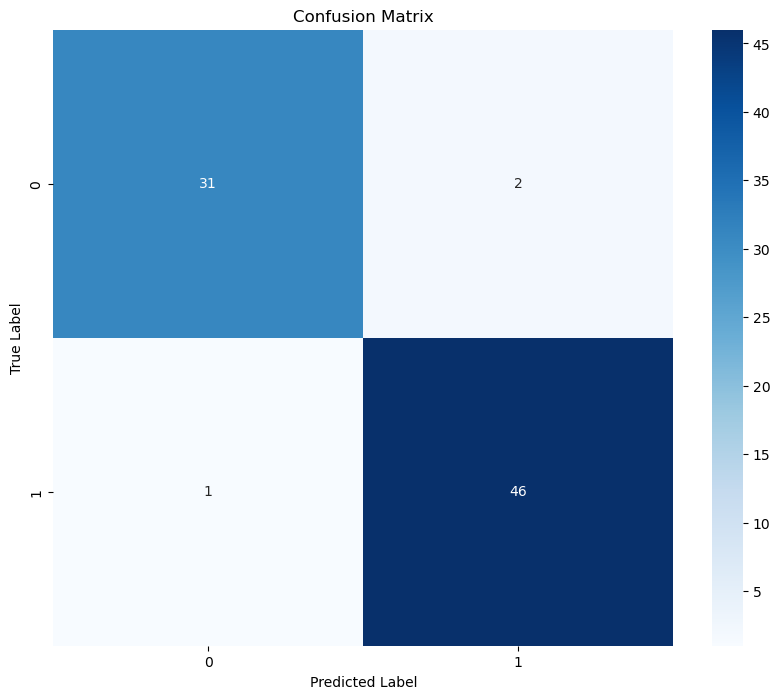

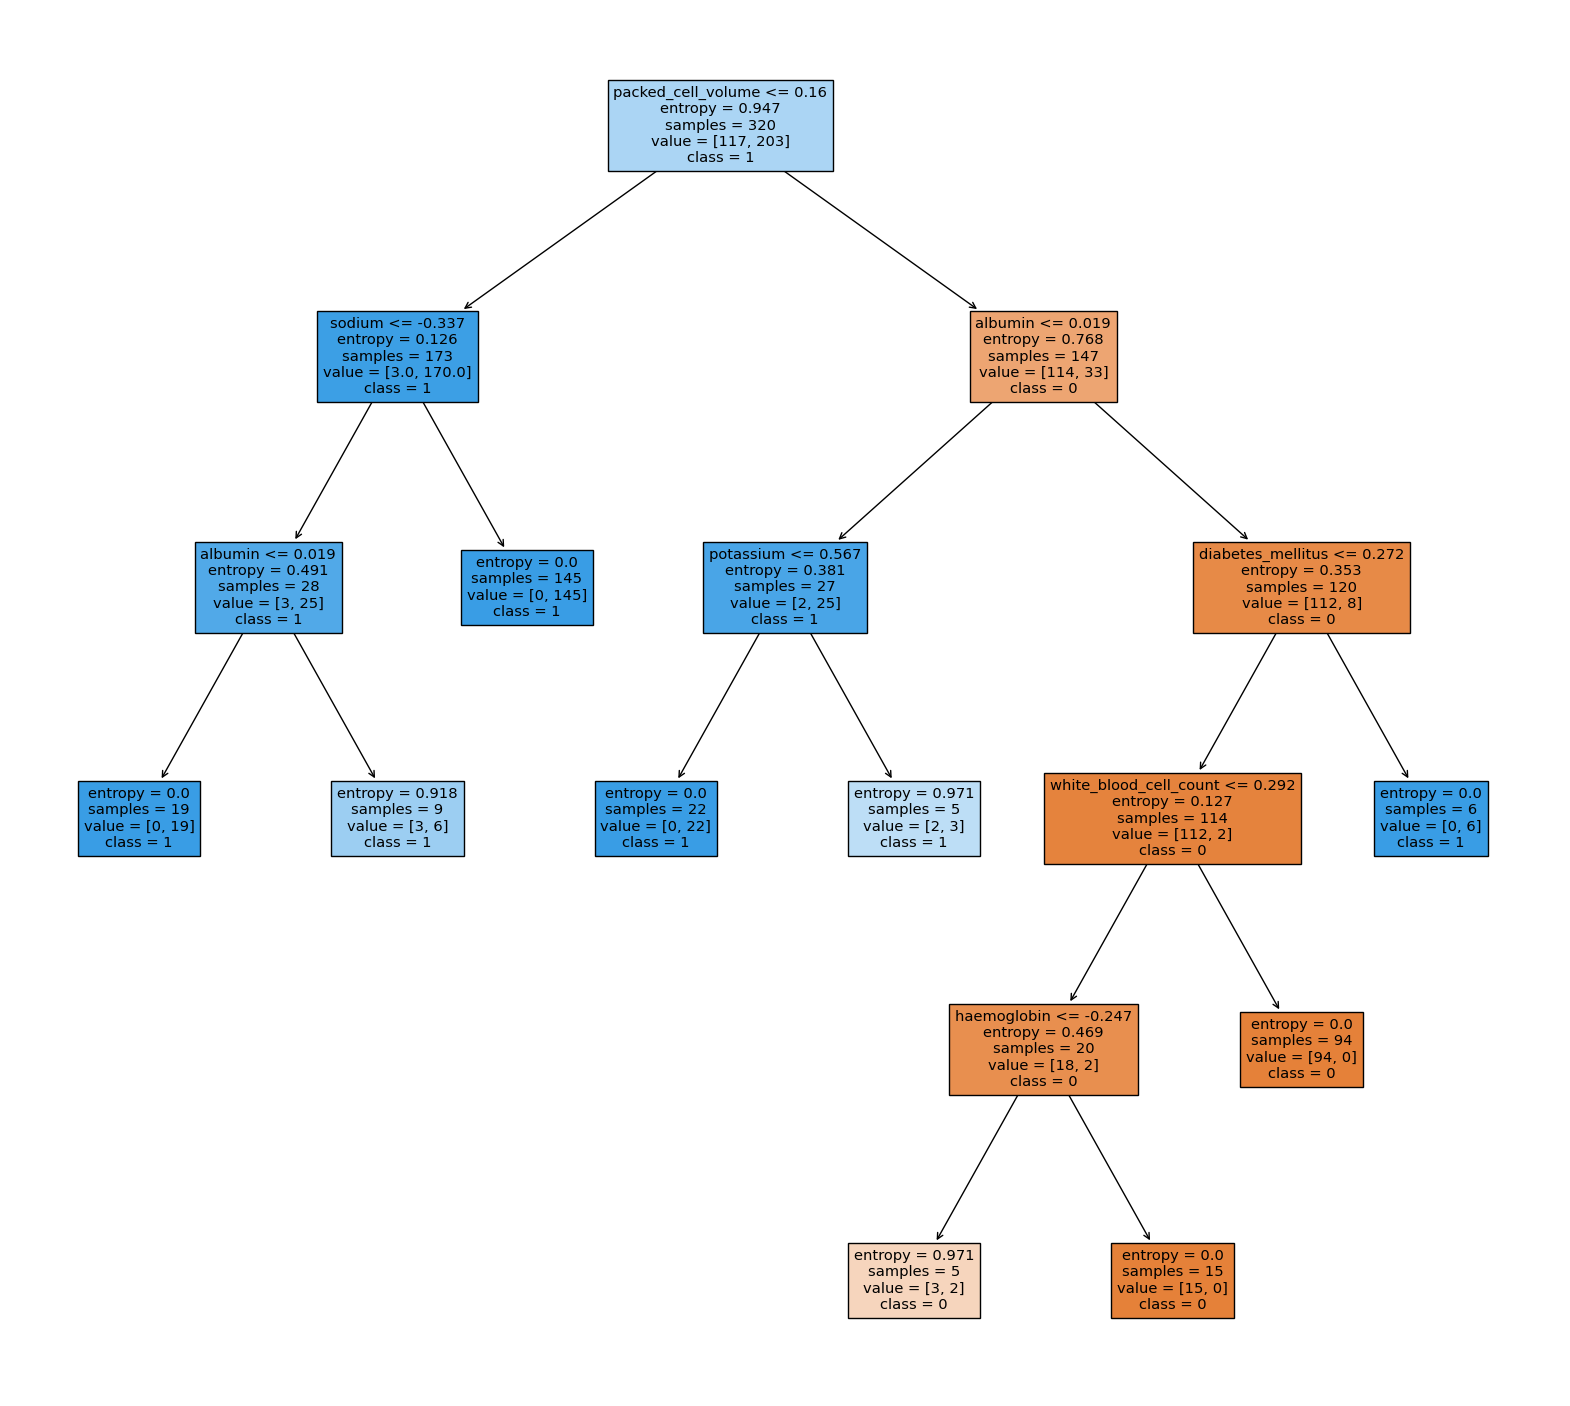

['DecisionTreeClassifier.pkl']

In [85]:
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

os.chdir(base_dir)
create_dir('DecisionTreeClassifier')

param_grid = {"max_depth": [3, 5, 7, 10, 15, 20, None],
              "max_features": [None, 'sqrt', 'log2'],
              "min_samples_leaf": [1, 3, 5, 10, 20],
              "criterion": ["gini", "entropy"]}

grid = GridSearchCV(DecisionTreeClassifier(), param_grid, refit=True, verbose=1, cv=5)
DT_model = grid.fit(X_train, y_train).best_estimator_

best_params = grid.best_params_
print(f"Best params: {best_params}")

y_train_prob = DT_model.predict_proba(X_train)[:, 1]
y_test_prob = DT_model.predict_proba(X_test)[:, 1]

print_score(DT_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=True)
dtc_acc, dtc_ra =print_score(DT_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=False)
plt.figure(figsize=(20, 18))
tree.plot_tree(DT_model, feature_names = df.columns.tolist()[1:], filled=True, class_names=["0", "1"])
plt.savefig("DECISION TREE")
plt.show()
joblib.dump(DT_model,'DecisionTreeClassifier.pkl')

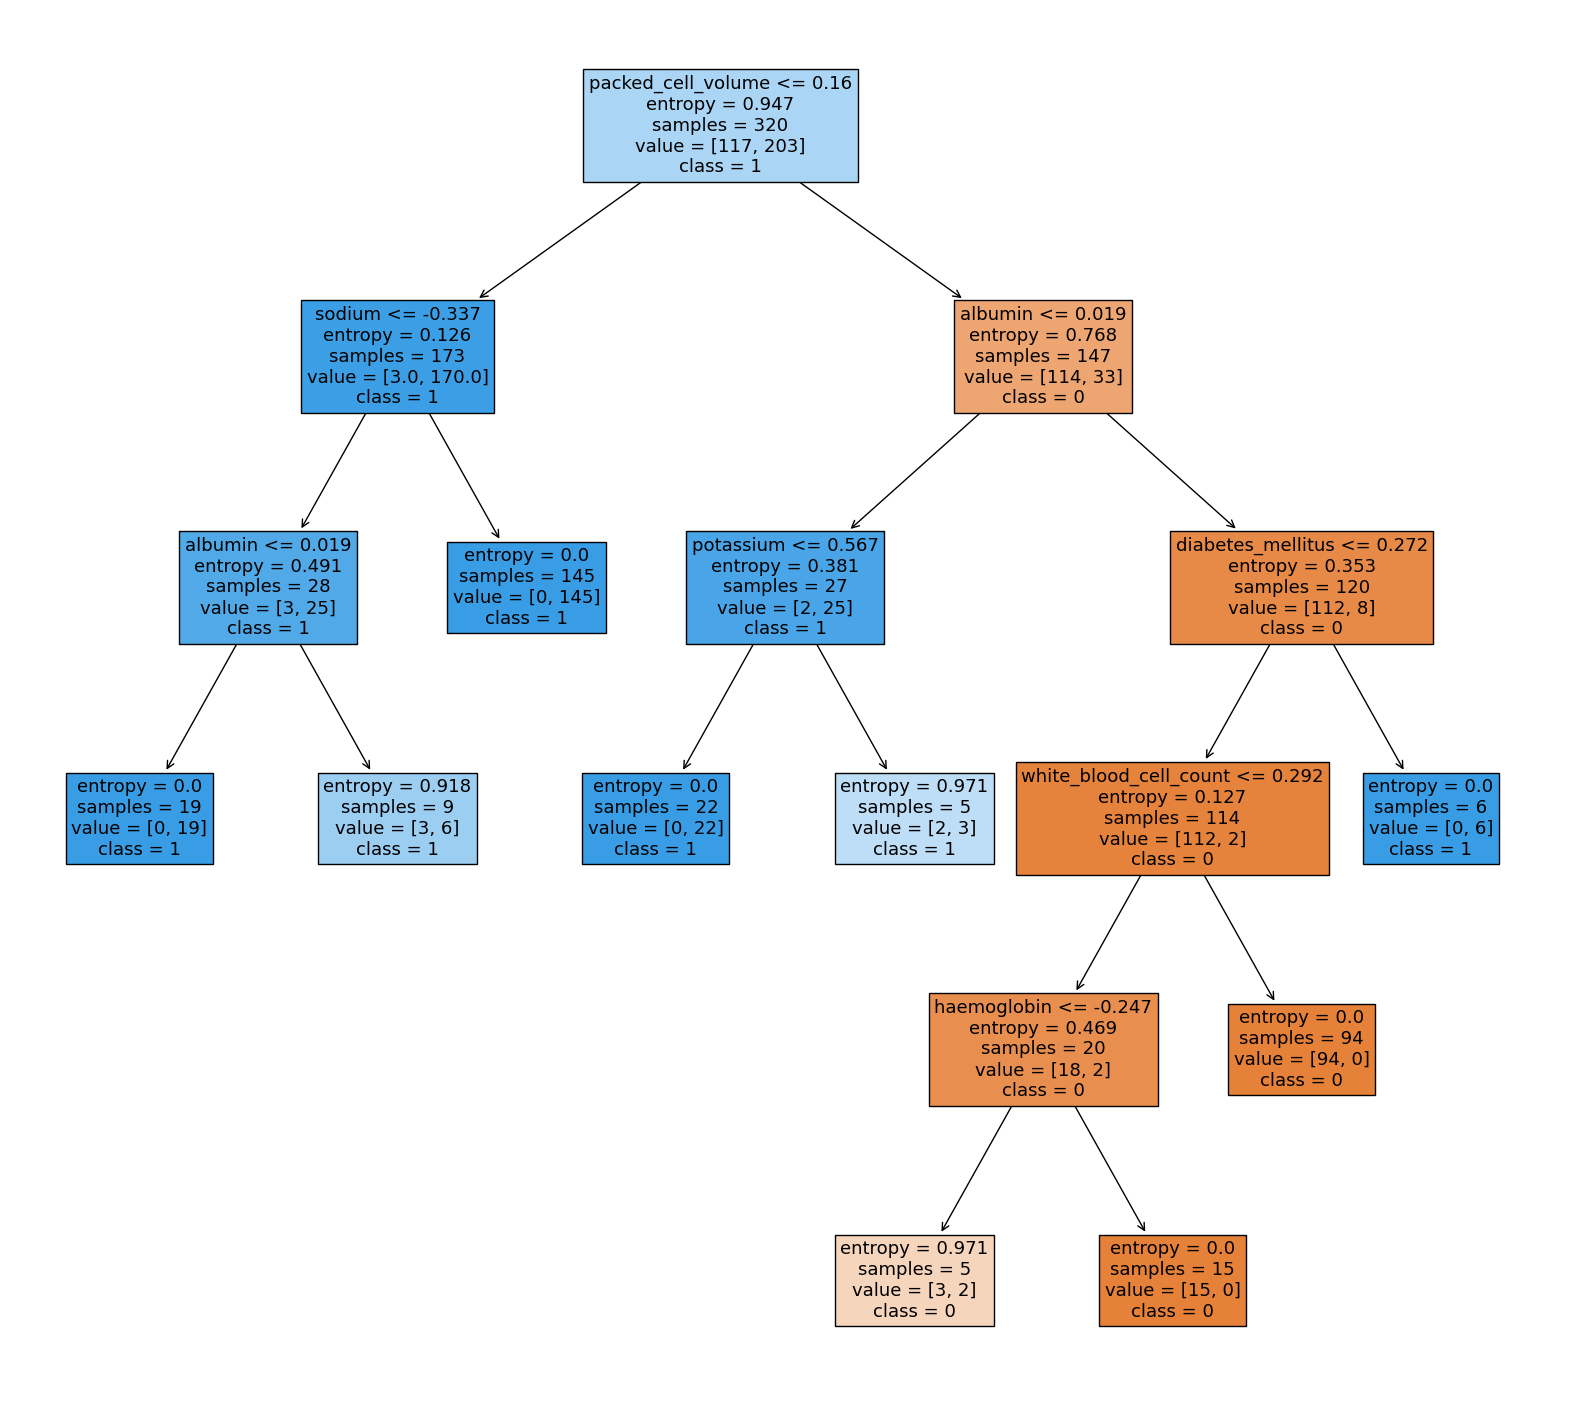

In [91]:
plt.figure(figsize=(20, 18))
tree.plot_tree(DT_model, 
               feature_names=df.columns.tolist()[1:], 
               filled=True, 
               class_names=["0", "1"],
               fontsize=13)  # Set the fontsize parameter to the desired value
plt.savefig("DECISION TREE")
plt.show()

# RANDOM FOREST

Saving in directory: C:\Users\Tharunraj_S\Desktop\Mini_project\Codes\ML logs copy\models\RandomForestClassifier
Fitting 5 folds for each of 360 candidates, totalling 1800 fits
Best params: {'bootstrap': True, 'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'min_samples_split': 2, 'n_estimators': 50}


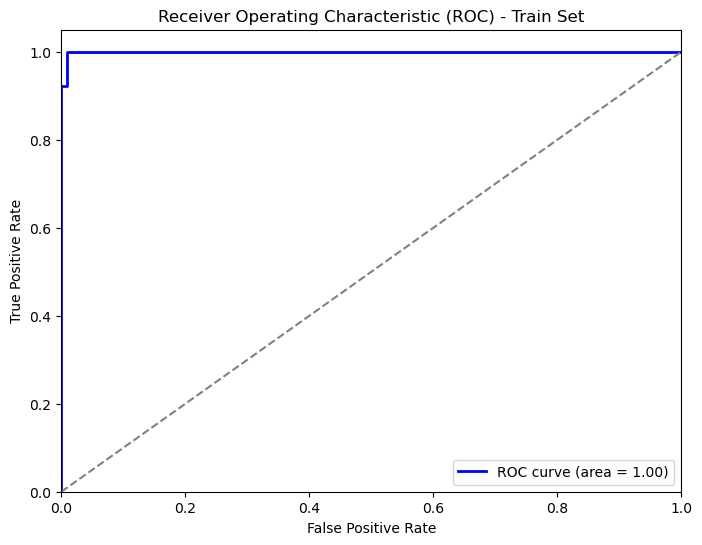

Train Result:
Accuracy Score: 99.69%
_______________________________________________
ROC AUC Score: 99.93%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       117
           1       1.00      1.00      1.00       203

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320

_______________________________________________
Confusion Matrix: 
 [[116, 1], [0, 203]]



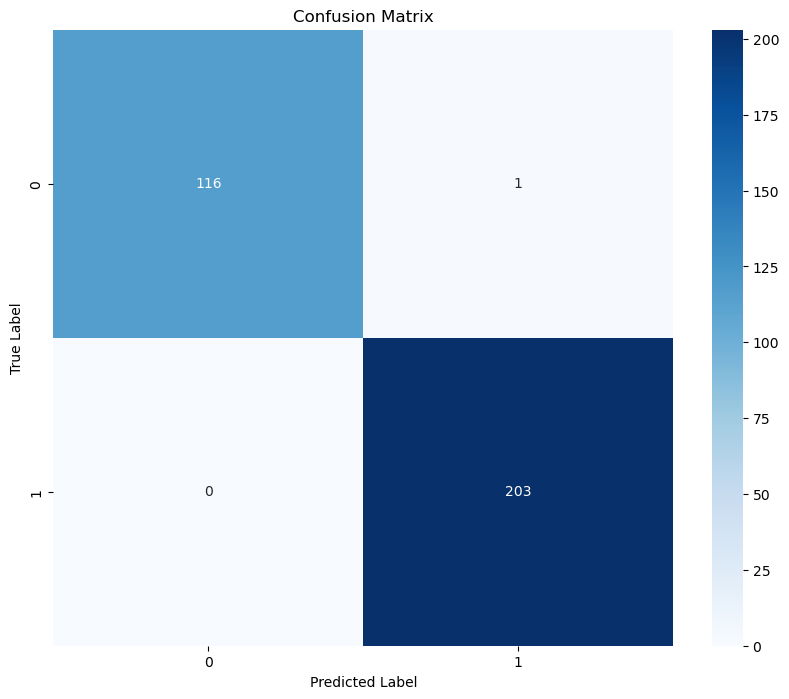

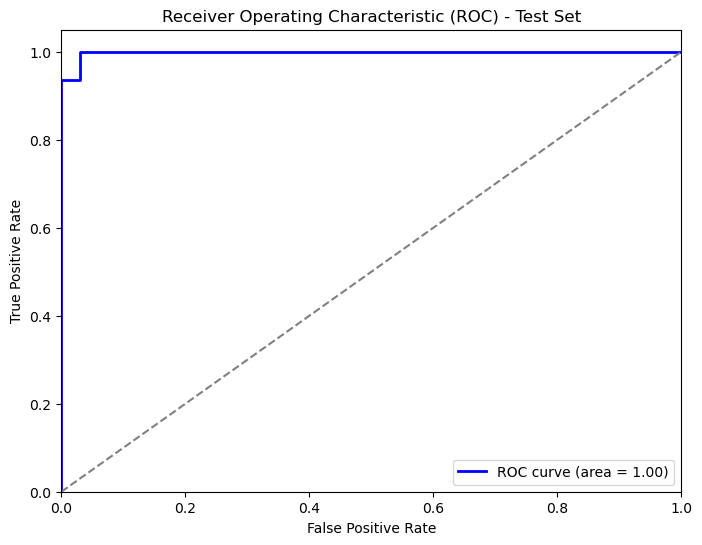

Test Result:
Accuracy Score: 98.75%
_______________________________________________
ROC AUC Score: 99.81%
_______________________________________________
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        33
           1       0.98      1.00      0.99        47

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80

_______________________________________________
Confusion Matrix: 
 [[32, 1], [0, 47]]



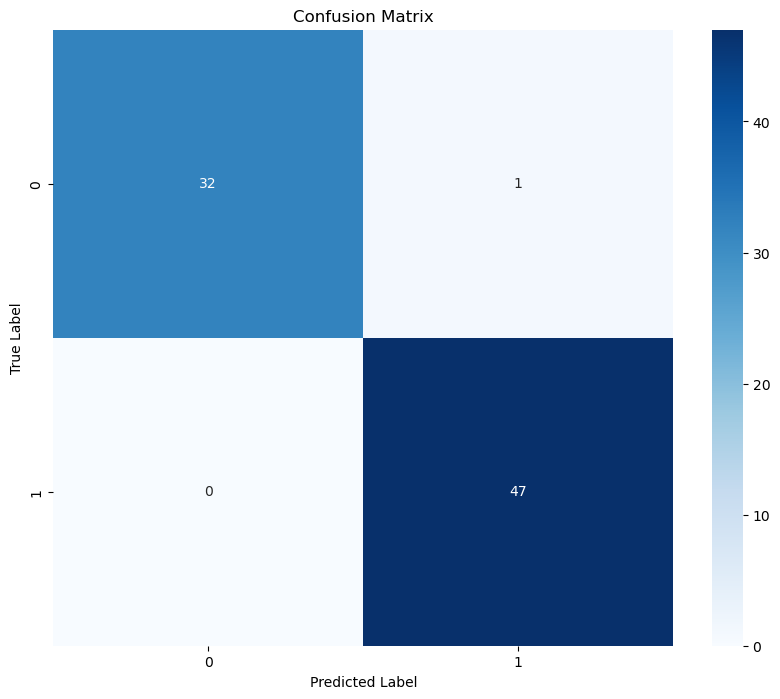

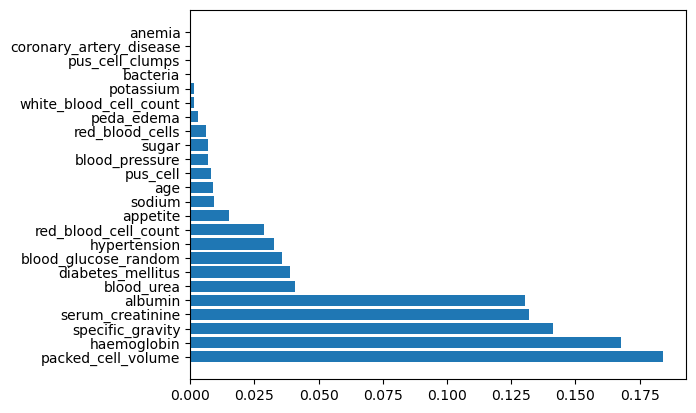

['RandomForestClassifier.pkl']

In [86]:
from sklearn.ensemble import RandomForestClassifier

os.chdir(base_dir)
create_dir('RandomForestClassifier')

param_grid = {'bootstrap': [True, False],
            'max_depth': [None, 5, 10, 15, 20],
            'max_features': [None, 'sqrt'],
            'min_samples_leaf': [1, 10, 20],
            'min_samples_split': [2, 10, 20],
            'n_estimators': [50, 100]}

grid = GridSearchCV(RandomForestClassifier(), param_grid, refit=True, verbose=1, cv=5)
RF_model = grid.fit(X_train, y_train).best_estimator_

best_params = grid.best_params_
print(f"Best params: {best_params}")

y_train_prob = RF_model.predict_proba(X_train)[:, 1]
y_test_prob = RF_model.predict_proba(X_test)[:, 1]

print_score(RF_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=True)
rd_clf_acc, rd_clf_ra =print_score(RF_model, X_train, y_train, X_test, y_test, y_train_prob, y_test_prob, train=False)
rfi=pd.Series(RF_model.feature_importances_, index=df.columns.tolist()[:-1]).sort_values(ascending=False)
plt.barh(rfi.index,rfi.values)
plt.savefig("RFC")
plt.show()
joblib.dump(RF_model,'RandomForestClassifier.pkl')

In [87]:
# Table Comparison on models
models = pd.DataFrame({
    'Model' : ['Logistic Regression', 'KNN', 'Decision Tree Classifier', 'Random Forest Classifier'],
    'Accuracy Score' : [lr_acc, knn_acc, dtc_acc, rd_clf_acc],
    'ROC/AUC Score' : [lr_ra, knn_ra, dtc_ra, rd_clf_ra]})
    
models.sort_values(by = 'Accuracy Score', ascending = False)

,Model,Accuracy Score,ROC/AUC Score
3,Random Forest Classifier,98.75,99.806576
0,Logistic Regression,97.50,99.871051
2,Decision Tree Classifier,96.25,98.807221
1,KNN,93.75,94.680851


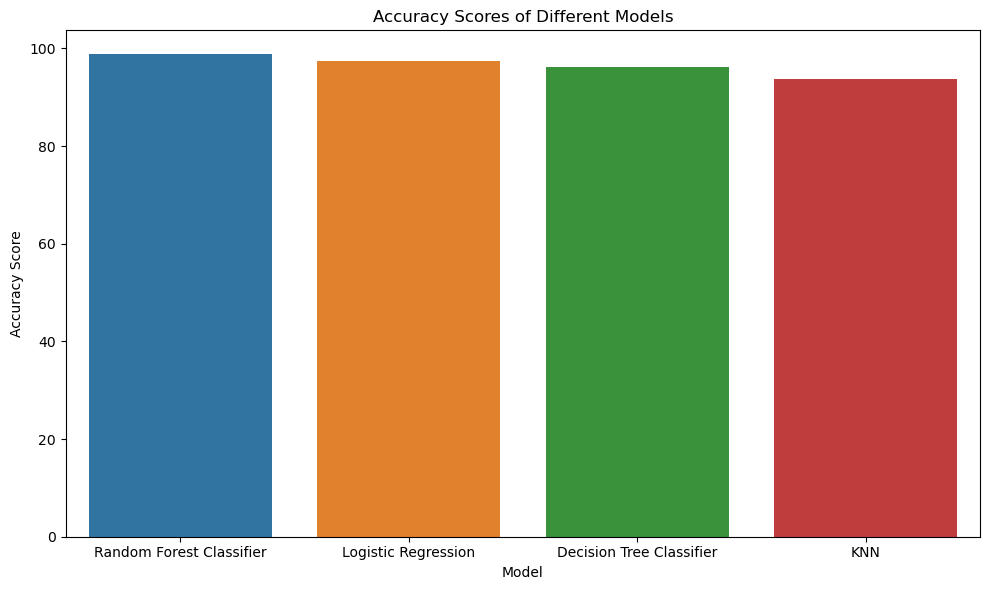

In [88]:
# Create a bar plot
comparison_path=os.path.join(base_dir, 'comparison.png')
plt.figure(figsize=(10, 6))
sns.barplot(data=models.sort_values(by = 'Accuracy Score', ascending = False), x='Model', y='Accuracy Score')
plt.title('Accuracy Scores of Different Models')
plt.ylabel('Accuracy Score')
plt.tight_layout()
plt.savefig(comparison_path)
plt.show()